# [이론] 토픽 검증 — 원문 읽기·시드 안정성·LLM 이름

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 왜 토픽을 검증하는가

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 비정형 데이터(자연어)</div>
<h1 style="color:#000000;margin:10px 0">토픽 검증 — 원문 읽기·시드 안정성·LLM 이름</h1>
<div style="font-size:1.05em;color:#656565">BERTopic 으로 찾은 토픽을 세 가지 확인으로 검증해 테마로 쓸 토픽을 고르고, 테마마다 코드북 항목을 씁니다</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)는 선택입니다.

### 핵심 질문: 토픽 하나를 테마로 써도 되는가 [필수]

**예시 토픽 「헬스장」** 은 토픽 모델링 수업의 헬스장 해지 문장 3개를 민원 200건으로 늘렸다고 가정한 가상의 토픽입니다. 실제 민원 2만 건에 같은 확인을 한 결과는 「6. 민원 2만 건 검증과 팀 라운드」에 모았습니다.

BERTopic 은 이 토픽의 상위 단어 · 대표 문서 · 민원 수를 줍니다. 대표 문서는 상위 단어에 가장 잘 맞는 민원입니다. LLM(대규모 언어 모델)에는 상위 단어와, 상위 단어에 잘 맞는 순서로 앞 4건의 민원을 입력합니다. 그러면 이름 초안 「회원권 환불 민원」을 얻습니다.

**월간 불만 요약** 은 매달 민원을 유형별 건수로 정리해 CX 팀장에게 보내는 요약입니다.

> BERTopic 이 낸 토픽 하나를 이름과 비율 그대로 월간 불만 요약에 써도 되는가?

다른 시드에서도 다시 나오는 토픽이면 비율은 그대로 쓰고, 이름은 확인한 뒤에 씁니다. 비율은 그 토픽에 배정된 민원 수로 정해지고, 이름을 고쳐도 배정은 바뀌지 않습니다.

**이름은 왜 확인해야 하나요?**

이름 초안은 LLM 에 상위 단어와, 상위 단어에 가장 잘 맞는 민원 4건만 입력해 얻은 이름입니다. 나머지 196건에도 이 이름이 맞는지는 아직 모릅니다.

**확인을 거친 토픽은 무엇이 되나요?**

- **테마(theme)** 는 월간 불만 요약에서 민원을 나누어 집계하는 불만 유형입니다. 세 가지 확인을 거친 토픽만 테마가 됩니다. 예시 토픽은 확인을 거쳐 테마 「헬스장·운동 강습 해지 환불」이 됩니다.
- **코드북(codebook)** 은 테마마다 이름 · 정의 · 포함 기준 · 제외 기준 · 예를 적은 기준표입니다. 사람이나 LLM 이 민원을 한 건씩 읽고 테마로 나눌 때, 누가 나누어도 같은 민원이 같은 테마가 되게 합니다.

### 세 가지 확인은 어떤 가정을 확인하는가 [필수]

예시 토픽을 「회원권 환불 민원」이라고 부르는 데에는 확인하지 않은 가정이 세 가지 있습니다. BERTopic 의 기본 토픽 표에는 세 가정을 확인한 결과가 없습니다. **세 가지 확인** 은 이 가정을 하나씩 확인하는 원문 읽기 · 시드 안정성 · 이름 확인입니다.

| 확인 | 확인하는 가정 | 하는 일 | 가정이 틀리면 |
|---|---|---|---|
| 원문 읽기 | 토픽의 민원이 모두 한 사건을 말한다 | 대표 문서 1건과 무작위로 고른 민원 · 가장자리의 민원 4건을 골라, 4건이 대표 문서와 같은 사건인지 읽는다 | 사건들을 아우르는 이름을 짓는다 |
| 시드 안정성 | 시드(난수의 시작값)를 바꿔도 토픽이 다시 나온다 | 시드를 바꿔 다시 나눴을 때, 이 토픽과 민원이 절반 넘게 겹치는 토픽이 있는지 본다 | 큰 토픽에 합쳐져 따로 나오지 않으면 테마로 쓰지 않는다 |
| 이름 확인 | 이름이 토픽의 민원 대부분에 맞는다 | 무작위 10건 가운데 8건 이상이 이름에 맞는지 본다 | 이름을 고쳐 새 10건으로 다시 확인한다 |

- 원문 읽기: 상위 단어에 가장 잘 맞는 민원은 헬스장 해지 환불입니다. 그런데 무작위로 고른 민원과 토픽 가장자리의 민원에는 트레이너 불친절 · 필라테스 · 수영장 민원이 있어, 사건이 여럿인 토픽입니다.
- 시드 안정성: 예시 토픽 「헬스장」은 다른 시드에서도 다시 나온다고 가정합니다. 작은 토픽이 더 큰 토픽에 합쳐져 따로 나오지 않는 경우는 「2. 시드 안정성」의 문서 12건 예로 봅니다.
- 이름 확인: 초안 「회원권 환불 민원」은 무작위 10건 가운데 8건에 맞습니다. 그래도 어느 시설인지가 없는 넓은 이름이라 고치고, 고친 이름도 새 10건으로 다시 확인합니다.

세 가정은 서로 별개라, 하나가 맞아도 나머지가 맞는지는 알 수 없습니다. 이름이 10건 가운데 8건에 맞아도, 그 토픽이 다른 시드에서 다시 나오는지는 모릅니다.

<img src="https://ebhtmardjzsiyxjncvbb.supabase.co/storage/v1/object/public/images/12-nlp-unstructured/d5-topic-to-theme.png" alt="예시 토픽 「헬스장」 상자에서 원문 읽기, 시드 안정성, 이름 확인 상자를 차례로 지나 테마 「헬스장·운동 강습 해지 환불」 상자로 가는 흐름도. 확인마다 아래에 거르지 않음, 테마로 쓰지 않음, 이름을 고쳐 다시 상자가 있고, 맨 아래 코드북 항목에 이름 · 정의 · 포함 기준 · 제외 기준 · 예가 적혀 있다" width="830" height="410" />
<p align="center"><em>▲ 가상의 예다. 남색 상자는 세 가지 확인이고, 회색 점선 상자는 확인 결과에 따라 하는 일이다. 하늘색 상자는 확인을 마친 테마와 그 코드북 항목이다</em></p>

<div class="lms-summary">

**정리**

다른 시드에서도 다시 나오는 토픽이면 비율은 그대로 쓰고, 이름은 확인한 뒤에 씁니다. 예시 토픽의 「회원권 환불 민원」도 상위 단어와, 상위 단어에 가장 잘 맞는 민원 4건만 LLM 에 입력해 얻은 초안입니다. 확인하기 전에는 토픽 이름으로 쓰지 않습니다.

세 가정은 서로 별개라, 확인 하나를 통과해도 나머지를 건너뛰지 않습니다.

**할 일**

- 테마로 쓸 토픽은 원문 읽기 · 시드 안정성 · 이름 확인을 모두 거칩니다
- 확인을 거친 테마마다 코드북 항목을 씁니다

다른 시드에서 따로 나오지 않는 토픽은 이름 확인을 통과해도 테마로 쓰지 않습니다.

</div>

## 1. 원문 읽기

예시 토픽 「헬스장」의 민원은 모두 헬스장 해지 환불이라는 한 사건을 말할까요? 대표 문서에 무작위 문서 3건과 경계 문서 1건을 더해 5건을 읽으면, 4건 가운데 3건이 다른 사건이나 제품을 말합니다. 이런 토픽은 빼지 않고, 사건들을 아우르는 이름을 짓습니다.

### 대표 문서만 읽으면 무엇을 놓치는가 [필수]

BERTopic 으로 토픽을 만들 때는 상위 단어와 **대표 문서**로 토픽의 내용을 파악했습니다. 대표 문서는 토픽 안에서 c-TF-IDF 로 상위 단어에 가장 잘 맞는 민원 한 건입니다.

그런데 대표 문서는 상위 단어에 맞춰 고른 민원이라, 늘 상위 단어와 같은 내용으로 보입니다. 예시 토픽의 대표 문서 「헬스장 회원권 중도 해지 환불 요청」도 상위 단어 헬스장 · 환불 · 해지와 같은 이야기입니다. 대표 문서만 읽어서는 토픽에 사건이 여럿인지 알 수 없습니다.

**원문 읽기에서는 어떤 민원을 읽나요?**

대표 문서에 무작위 문서 3건과 경계 문서 1건을 더해 토픽마다 5건을 읽습니다.

| 종류 | 건수 | 고르는 방법 | 알 수 있는 것 |
|---|---:|---|---|
| 대표 문서 | 1 | c-TF-IDF 로 상위 단어에 가장 잘 맞는 민원 | 상위 단어가 나타내는 토픽 |
| 무작위 문서 | 3 | 토픽의 민원 가운데 난수로 고른 민원 | 토픽의 보통 민원 |
| 경계 문서 | 1 | 소속 확률이 가장 낮은 민원 | 토픽 가장자리에 어떤 민원이 있는가 |

무작위 · 경계 문서 4건은 상위 단어와 상관없이 고른 민원이라, 대표 문서와 다른 사건이 있으면 여기서 드러납니다.

**소속 확률(membership probability)** 은 민원이 자기 토픽에 얼마나 강하게 속하는지 나타내는 0～1 값입니다. 토픽 모델링을 배울 때 본 HDBSCAN 이, 밀도가 높은 영역을 군집으로 고르면서 민원마다 함께 계산합니다.

```text
0 (토픽 가장자리, 경계 문서 쪽) ──────────── 1 (밀도가 높은 군집 한가운데)
```

<img src="https://ebhtmardjzsiyxjncvbb.supabase.co/storage/v1/object/public/images/12-nlp-unstructured/hdbscan-advanced-5-1.png" alt="합성 2차원 점을 HDBSCAN 으로 나눈 산점도, 여섯 색 군집과 회색 점, 군집 가장자리의 옅은 점" width="560" height="386" />
<p align="center"><em>▲ 가로 · 세로는 합성 2차원 자료에서 점의 위치다. 색마다 한 군집이고 회색 점은 어느 군집에도 속하지 않은 이상치(BERTopic 의 토픽 −1)다. 같은 색 안에서 옅은 점일수록 소속 확률이 낮다 (출처: hdbscan 공식 문서 「Getting More Information About a Clustering」, scikit-learn-contrib/hdbscan, BSD-3-Clause)</em></p>

경계 문서는 같은 색 안에서 가장 옅은 점에 해당합니다.

**소속 확률이 가장 큰 민원을 대표 문서로 쓰면 되지 않을까요?**

HDBSCAN 은 밀도가 높은 영역 한가운데의 민원 여럿에 똑같이 1.0 을 줍니다. 그래서 소속 확률로는 한 건을 고를 수 없고, 대표 문서는 c-TF-IDF 로 고릅니다.

**5건을 읽은 뒤에는 무엇을 판단하나요?**

무작위 · 경계 문서가 대표 문서와 같은 사건을 말하는지 판단합니다.

> 무작위 · 경계 4건 가운데 2건 이상이 대표 문서와 다른 제품이나 사건을 말하면 **사건이 여럿인 토픽**이다. 1건 이하면 **사건이 하나인 토픽**이다.

경계 문서는 원래 토픽 가장자리라 대표 문서와 다를 수 있어, 1건이 아니라 2건 이상 다를 때 사건이 여럿이라고 봅니다.

제품만 다른 민원도 다른 1건으로 봅니다. 사건이 같아도 제품이 다르면 한 이름으로 부르기 어렵기 때문입니다. 그래서 여러 제품을 아우르는 이름이 필요하다는 신호로 삼습니다.

**원문 검토 결과** 는 이 기준으로 토픽마다 내린 「사건이 여럿 / 하나」 판단입니다. 원문 읽기는 5건을 읽는 일이고, 원문 검토 결과는 읽고 나서 내린 판단입니다.

<details class="lms-extra"><summary>자세히 — 대표 · 무작위 · 경계 문서를 고르는 방법</summary>

대표 문서의 「가장 잘 맞는다」는 c-TF-IDF(상위 단어를 고를 때 쓴 단어 점수)로 정합니다. 토픽 표를 만들 때는 토픽의 민원을 합친 글 하나에 점수를 매겼습니다. 민원 한 건도 토픽 하나처럼 보고 같은 식으로 점수를 매깁니다.

점수는 단어가 나온 횟수를 명사 수로 나눈 tf 에, 토픽 표를 만들 때 쓴 단어별 로그 항을 곱한 값입니다.

이렇게 만든 민원의 점수 목록과 토픽의 점수 목록 사이의 코사인 유사도가 가장 큰 민원이 대표 문서입니다.

| 차례 | 할 일 | 기준 |
|---|---|---|
| ① 대표 | 토픽 안 민원마다 c-TF-IDF 벡터를 만든다 | 토픽 표를 만들 때의 식 그대로 |
| ② 대표 | 토픽의 c-TF-IDF 벡터와 코사인을 구한다 | 가장 큰 민원, 같으면 소속 확률이 큰 쪽 |
| ③ 무작위 | 난수 생성기 하나를 만든다 | `numpy.random.default_rng(0)` |
| ④ 무작위 | 번호가 작은 토픽부터 차례로 3건씩 고른다 | 같은 생성기를 이어서 쓴다 |
| ⑤ 경계 | 토픽 안 소속 확률을 비교한다 | 가장 낮은 민원 |

</details>

<details class="lms-extra"><summary>더 깊이 — 토픽 일관성 지표 coherence 와 그 한계</summary>

**coherence(토픽 일관성)** 는 원문을 읽지 않고 상위 단어만으로 토픽을 평가하는 자동 지표입니다.

상위 단어를 2개씩 골라 두 단어가 같은 문서에 함께 나오는 정도를 계산해 평균한 값입니다. 두 단어가 따로 나오는 횟수에 비해 함께 나오는 문서가 많을수록 값이 큽니다.

그런데 이런 자동 지표와 사람의 판단이 일치하지 않는다는 연구가 있습니다.

- Chang 외 2009(「Reading Tea Leaves」, NeurIPS): 우도가 더 높은 모델이 사람에게는 더 읽기 어려운 토픽을 내는 경우가 많았습니다. 우도는 학습에 쓰지 않은 새 문서를 모델이 얼마나 그럴듯하게 설명하는지 매긴 점수입니다.
- Hoyle 외 2021(「Is Automated Topic Model Evaluation Broken?」, NeurIPS): coherence 로는 한 모델이 낫다고 나왔지만 사람이 토픽을 평가한 결과에서는 그 차이가 나타나지 않았습니다.

게다가 coherence 는 상위 단어만으로 계산하므로, 이 값으로는 토픽의 민원에 사건이 여럿인지 알 수 없습니다. 사건은 원문을 읽어 확인합니다.

</details>

### 예시 토픽의 5건은 같은 사건을 말하는가 [필수]

예시 토픽 「헬스장」에서 대표 · 무작위 · 경계 세 방법으로 5건을 골랐습니다. **원문 검토 표** 는 토픽마다 고른 5건이 대표 문서와 같은 사건인지 정리한 표입니다.

| 종류 | 민원 제목 | 소속 확률 | 대표 문서와 비교 |
|---|---|---:|---|
| 대표 | 헬스장 회원권 중도 해지 환불 요청 | 1.0 | (비교 기준) |
| 무작위 | 헬스장 중도 해지 위약금이 과합니다 | 0.93 | 같은 사건(헬스장 해지의 돈 문제) |
| 무작위 | 헬스장 트레이너가 너무 불친절해요 | 0.71 | 다른 사건(이용 불만) |
| 무작위 | 필라테스 수강권 환불을 거절당했어요 | 0.64 | 다른 제품(필라테스) |
| 경계 | 수영장 강습 취소 환불 문의 | 0.38 | 다른 제품(수영장) |

무작위 · 경계 4건 가운데 3건이 대표 문서와 다르므로, 예시 토픽은 사건이 여럿인 토픽입니다.

- 트레이너 불친절은 같은 헬스장 민원이지만 해지 · 환불이 아닌 이용 불만입니다.
- 필라테스 · 수영장 민원은 해지 · 환불을 말하지만 제품이 헬스장이 아닙니다.

트레이너 불친절 민원은 소속 확률이 0.71 이라 토픽 가장자리가 아닙니다. 경계 문서만 읽었다면 놓쳤을 민원이라, 무작위 문서를 함께 읽습니다.

**사건이 여럿인 토픽은 테마에서 빼나요?**

빼지 않습니다. 원문 읽기는 토픽을 빼는 확인이 아니라 이름과 포함 기준을 정하는 근거입니다. 예시 토픽도 배정과 비율은 그대로 씁니다. 대신 해지 · 환불 사건과 운동 시설 · 강습을 아우르는 이름을 짓고, 사건마다 원문을 인용합니다.

트레이너 불친절처럼 이름 밖의 민원도 이 토픽에 배정된 민원이라 이번 달 건수에는 그대로 포함됩니다. 민원을 한 건씩 다시 나눌 때는 코드북의 제외 기준을 따릅니다(「5. 코드북」).

<div class="lms-summary">

**정리**

대표 문서는 상위 단어에 맞춰 고른 민원이라, 사건이 하나인지는 무작위 · 경계 문서로 판단합니다. 사건이 여럿인 토픽도 배정과 비율은 그대로 쓰고, 사건들을 아우르는 이름을 짓습니다.

**할 일**

- 토픽마다 대표 1건 · 무작위 3건 · 경계 1건을 읽고 원문 검토 결과를 정합니다
- 무작위 · 경계 4건 가운데 2건 이상이 다른 제품이나 사건이면 사건이 여럿인 토픽으로 봅니다

다른 사건은 경계 문서가 아닌 무작위 문서에서도 나오므로, 경계 문서만 읽고 끝내지 않습니다.

</div>

> **[문제] 예시 토픽 「헬스장」의 대표 문서 「헬스장 회원권 중도 해지 환불 요청」만 읽고 이름을 정했습니다. 이 방법으로는 무엇을 놓칠까요?**
>
> 1. 대표 문서는 c-TF-IDF 로 토픽에 가장 잘 맞는 문서라, 토픽의 보통 문서가 다른 사건을 말해도 드러나지 않는다
> 2. 대표 문서는 무작위로 고른 문서라 다시 고르면 바뀐다
> 3. 대표 문서는 소속 확률이 가장 낮은 문서라 토픽 밖 이야기다

## 2. 시드 안정성

시드만 바꿔 다시 적합해도 같은 토픽이 나올까요?

대부분의 토픽은 다시 나오지만, 작은 토픽은 다른 시드에서 더 큰 토픽에 합쳐질 수 있습니다. 그래서 테마로 쓸 토픽마다 다른 시드에서도 따로 나오는지 확인합니다.

**시드 안정성**은 시드만 바꿔 다시 적합해도 같은 민원들로 이루어진 토픽이 다시 나오는지를 말합니다. 필수 머신러닝의 군집화 수업에서도 K-Means 군집이 초기값을 바꿔도 비슷하게 나오는지로 안정성을 확인했습니다.

**BERTopic 에서 난수를 쓰는 단계는 어디인가요?**

1,024차원 임베딩을 5차원으로 줄이는 UMAP 단계입니다. 같은 자료에 UMAP 을 시드 없이 두 번 실행하면 군집의 모양과 위치가 달라집니다.

<img src="https://ebhtmardjzsiyxjncvbb.supabase.co/storage/v1/object/public/images/12-nlp-unstructured/umap-reproducibility-6-1.png" alt="MNIST 손글씨 숫자를 UMAP 으로 줄인 첫 번째 실행, 색 군집 10개" width="380" height="380" />
<img src="https://ebhtmardjzsiyxjncvbb.supabase.co/storage/v1/object/public/images/12-nlp-unstructured/umap-reproducibility-10-1.png" alt="같은 자료를 UMAP 으로 다시 줄인 두 번째 실행, 가운데 군집의 모양이 다르다" width="380" height="380" />
<p align="center"><em>▲ 가로 · 세로는 UMAP 이 2차원으로 줄인 점의 위치이고, 색은 손글씨 숫자 0～9 다. 같은 MNIST 손글씨 숫자 자료에 UMAP 을 시드 없이 두 번 실행했다. 왼쪽이 첫 번째, 오른쪽이 두 번째다 (출처: umap-learn 공식 문서 「UMAP Reproducibility」, Leland McInnes 외, BSD-3-Clause)</em></p>

토픽을 만들 때 UMAP 의 시드를 하나로 고정하면 같은 결과를 다시 얻을 수 있습니다. 그런데 그 토픽이 그 시드에서만 나오는 토픽인지는 모릅니다. 한 시드에서만 나오는 토픽은 다음 달 자료로 다시 적합하면 사라질 수 있습니다.

그래서 테마로 쓰기 전에 일부러 **시드만 바꿔** 다시 적합해 봅니다.

확인은 세 단계로 합니다. 단계마다 쓰는 값의 이름은 아래 소제목에서 정합니다.

```text
같은 민원 · 같은 설정
   ↓ ① 시드만 바꿔 여러 번 적합
시드마다 토픽 배정 하나
   ↓ ② 토픽마다 다른 시드에서 민원이 가장 많이 겹치는 토픽을 찾음
토픽 하나하나: 절반 넘게 겹치는 토픽이 있는가
   ↓ ③ 두 시드씩 배정 전체를 비교
배정 전체: 얼마나 같은지 수 하나로
```

- ① 바꾼 것은 시드뿐이라, 배정의 차이는 모두 시드에서 나옵니다.
- ② 토픽 번호는 시드마다 새로 매기므로, 같은 토픽인지는 함께 있는 민원으로 맞춥니다. 테마로 쓸 토픽이 다른 시드에서도 나오는지는 이 단계에서 알 수 있습니다.
- ③ 우연히 같아지는 만큼은 빼고 계산합니다.

②의 겹침은 자카드 계수와 대응 토픽으로, ③의 수는 ARI 로 나타냅니다.

### 두 시드의 토픽은 어떻게 맞추는가 [필수]

토픽 번호는 적합할 때마다 민원이 많은 토픽부터 0, 1, 2 … 로 새로 매깁니다. 크기가 비슷한 두 토픽은 시드에 따라 순서가 바뀌어 번호도 서로 바뀝니다.

따라서 두 시드의 토픽은 번호가 아니라 함께 있는 **민원**으로 맞춥니다.

가상의 작은 예로 봅니다. 민원 12건을 같은 설정으로 시드만 바꿔 두 번 적합했습니다. 민원은 문서 1～12 로 부르고, 토픽은 내용으로 부릅니다.

| 시드 | 토픽 | 속한 문서 |
|---|---|---|
| 0 | 휴대폰 요금 | 1～5 |
| 0 | 항공권 환불 | 6～9 |
| 0 | 여행사 패키지 환불 | 10～12 |
| 1 | 휴대폰 요금 | 1～5 |
| 1 | 여행·항공 환불 | 6～12 |

시드 1 에서는 항공권 환불과 여행사 패키지 환불의 문서가 한 토픽에 모였습니다.

**자카드 계수(Jaccard coefficient)** 는 두 토픽의 민원이 얼마나 겹치는지를 0～1 로 나타낸 값입니다. 자카드 유사도(Jaccard similarity)라고도 부릅니다. 자카드 유사도(Jaccard similarity)라고도 부릅니다.

$$
J(A, B) = \frac{\overbrace{|A \cap B|}^{\text{함께 있는 민원 수}}}{\underbrace{|A \cup B|}_{\text{어느 한쪽에라도 있는 민원 수}}}
$$

- $A$: 시드 0 의 토픽 하나에 있는 민원 집합. 예: 항공권 환불의 문서 6～9
- $B$: 시드 1 의 토픽 하나에 있는 민원 집합. 예: 여행·항공 환불의 문서 6～12

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Venn0001.svg" alt="겹친 두 원 가운데 겹친 면만 빨갛게 칠한 벤 다이어그램" width="320" height="233" />
<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Venn0111.svg" alt="겹친 두 원 전체를 빨갛게 칠한 벤 다이어그램" width="320" height="236" />
<p align="center"><em>▲ 원 하나가 토픽 하나의 민원 집합이다. 왼쪽 그림의 빨간 면은 두 토픽에 함께 있는 민원(분자)이고, 오른쪽 그림의 빨간 면은 어느 한쪽에라도 있는 민원(분모)이다 (출처: Wikimedia Commons 「Venn0001.svg」 · 「Venn0111.svg」, Watchduck, 퍼블릭 도메인)</em></p>

- 1 이면 두 토픽의 민원이 똑같습니다.
- 0.5 이상이면 함께 있는 민원이 어느 한쪽에라도 있는 민원의 절반 이상입니다.
- 0 이면 함께 있는 민원이 하나도 없습니다.

**어느 토픽끼리 같은 토픽인가요?**

시드 0 의 토픽마다 자카드 계수가 가장 큰 시드 1 토픽을 찾습니다. 이상치(−1)는 어느 토픽에도 배정되지 않은 민원이라 이 비교에서 뺍니다.

> **대응 토픽**은 다른 시드의 토픽 가운데 자카드 계수가 가장 크고, 그 값이 0.5 이상인 토픽이다.

작은 예의 세 토픽에 대입합니다.

| 시드 0 의 토픽 | 자카드 계수가 가장 큰 시드 1 토픽 | 자카드 계수 | 대응 토픽 |
|---|---|---:|---|
| 휴대폰 요금 | 휴대폰 요금 | 5 ÷ 5 = 1.0 | 있음 |
| 항공권 환불 | 여행·항공 환불 | 4 ÷ 7 ≈ 0.57 | 있음 |
| 여행사 패키지 환불 | 여행·항공 환불 | 3 ÷ 7 ≈ 0.43 | 없음 |

**패키지 환불은 3건이 모두 한 토픽에 있는데 왜 대응 토픽이 없나요?**

자카드 계수의 분모가 어느 한쪽에라도 있는 민원 수이기 때문입니다. 패키지 환불 3건은 시드 1 에서 흩어지지 않고 모두 여행·항공 환불에 있습니다. 그런데 그 토픽이 7건이라 분모가 7 이 되어 0.5 에 못 미칩니다.

분모로 패키지 환불의 민원 수 3 을 썼다면 3 ÷ 3 = 1 이 되어, 더 큰 토픽에 합쳐진 것이 드러나지 않습니다. 대응 토픽이 없으면 그 토픽은 다른 시드에서 따로 나오지 않습니다.

**0.5 를 넘는 시드 1 토픽이 둘 생길 수는 없나요?**

없습니다. 0.5 를 넘으려면 시드 0 토픽의 민원 절반보다 많이 함께 있어야 하기 때문입니다.

- 항공권 환불은 4건이라, 0.5 를 넘으려면 함께 있는 민원이 2건을 넘어야 합니다.
- 시드 1 의 토픽끼리는 민원이 겹치지 않으므로, 4건 가운데 3건 이상을 가진 시드 1 토픽은 하나뿐입니다.

그래서 0.5 를 기준으로 두면 대응 토픽이 하나로 정해집니다.

시드를 셋 이상 쓰면 한 시드를 기준으로 정합니다. 기준 시드의 토픽은 다른 시드 모두에서 대응 토픽이 있어야 통과합니다.

### 수정 Rand 지수(ARI) [필수]

**배정**은 민원마다 정해진 토픽 번호(이상치 −1 포함)입니다. 대응 토픽을 찾을 때는 이 배정을 토픽 하나씩 비교했습니다. 토픽 표 전체를 다시 얻을 수 있는지는 배정 전체를 한 값으로 나타낸 ARI 로 봅니다. ARI 는 민원을 2건씩 짝지은 **문서 쌍**으로 계산합니다.

**문서 쌍은 언제 일치하나요?**

한 문서 쌍이 두 실행 모두에서 「같은 토픽」이거나 모두에서 「다른 토픽」이면 그 쌍은 일치합니다. **Rand 지수(Rand index, RI)** 는 두 실행에서 일치한 문서 쌍의 비율입니다.

$$
\mathrm{RI} = \frac{\text{두 실행에서 일치한 문서 쌍 수}}{\text{전체 문서 쌍 수}}
$$

문서 A · B · C · D 를 두 번 나눈 작은 예로 계산해 봅니다.

- 실행 1: {A, B} {C, D}
- 실행 2: {A, B, C} {D}

| 문서 쌍 | AB | AC | AD | BC | BD | CD |
|---|---|---|---|---|---|---|
| 실행 1 | 같음 | 다름 | 다름 | 다름 | 다름 | 같음 |
| 실행 2 | 같음 | 같음 | 다름 | 같음 | 다름 | 다름 |
| 일치 | 예 | 아니요 | 예 | 아니요 | 예 | 아니요 |

일치한 문서 쌍은 AB · AD · BD 3개라 Rand 지수는 3 ÷ 6 = 0.5 입니다.

**Rand 지수 0.5 는 높은 값인가요?**

두 실행이 서로 아무 관계 없이 나뉘어도 우연히 일치하는 문서 쌍이 생깁니다. **수정 Rand 지수(adjusted Rand index, ARI)** 는 문서 쌍의 일치가 우연보다 얼마나 더 많은지를 나타낸 값입니다.

**기대 Rand 지수(expected Rand index, E[RI])** 는 서로 무관한 두 배정에서 기대되는 문서 쌍 일치율입니다. ARI 는 RI 에서 이 값을 빼고, 같은 배정이 1 이 되도록 다시 나눕니다.

$$
\mathrm{ARI} = \frac{\mathrm{RI} - \overbrace{E[\mathrm{RI}]}^{\text{기대 Rand 지수}}}{\underbrace{\max \mathrm{RI}}_{\text{가장 큰 값}} - E[\mathrm{RI}]}
$$

- $E[\mathrm{RI}]$: 기대 Rand 지수
- $\max \mathrm{RI}$: Rand 지수의 최댓값 1

- ARI 가 1 이면 두 배정이 같습니다. 토픽 번호만 바꾼 배정도 1 입니다.
- ARI 가 0 이면 일치한 문서 쌍이 우연히 기대되는 만큼뿐입니다.

작은 예의 두 실행이 서로 무관해도 6쌍 가운데 평균 3쌍은 우연히 일치합니다. 기대 Rand 지수가 3 ÷ 6 = 0.5 로 Rand 지수와 같아 ARI 는 0 입니다.

ARI 에는 정해진 합격선이 없습니다. 우연 수준 0 과 같은 배정 1 사이 어디쯤인지, 다른 방법보다 얼마나 높은지로 해석합니다.

<details class="lms-extra"><summary>자세히 — scikit-learn 으로 구한 작은 예의 ARI</summary>

scikit-learn `adjusted_rand_score([0, 0, 1, 1], [0, 0, 0, 1])` 로 계산해도 0.0 입니다.

</details>

**토픽이 많으면 우연한 일치는 어떻게 되나요?**

토픽이 많을수록 아무 두 민원은 대개 다른 토픽에 속하므로, 「둘 다 다른 토픽」인 일치가 저절로 늘어납니다.

<img src="https://scikit-learn.org/stable/_images/sphx_glr_plot_adjusted_for_chance_measures_002.png" alt="무작위 배정 두 개를 군집 수별로 비교한 여러 지표의 선 그래프" width="560" height="420" />
<p align="center"><em>▲ 가로축은 군집 수, 세로축은 지표 값(0～1)이다. 서로 무관한 무작위 배정 두 개를 비교했다. 주황 선이 Rand index, 초록 선이 ARI 이고 나머지 선은 다른 지표다 (출처: scikit-learn 공식 예제 「Adjustment for chance in clustering performance evaluation」, BSD-3-Clause, 합성 자료)</em></p>

예를 들어 토픽이 40개쯤으로 많으면, 민원을 무작위로 나눈 두 배정도 Rand 지수는 약 0.951 이고 ARI 는 0 근처입니다. 그래서 토픽이 많은 배정의 시드 안정성은 우연한 일치를 뺀 ARI 로 확인합니다.

<details class="lms-extra"><summary>자세히 — 기대 Rand 지수를 구하는 계산</summary>

**작은 예의 기대 Rand 지수 0.5**

두 실행이 서로 무관하게 나뉜다면 6쌍 가운데 몇 쌍이 우연히 일치할까요? 두 실행의 「같은 토픽」 쌍 개수는 바꾸지 않고 계산합니다.

| 차례 | 계산 | 값 |
|---|---|---:|
| ① 실행 1 에서 같은 토픽인 쌍 | AB · CD | 2 |
| ② 실행 2 에서 같은 토픽인 쌍 | AB · AC · BC | 3 |
| ③ 실행 1 의 같은 토픽 쌍 하나가 실행 2 에서도 같을 확률 | 3 ÷ 6 | 0.5 |
| ④ 둘 다 같은 토픽인 쌍의 기대 개수 | 2 × 3 ÷ 6 | 1 |
| ⑤ 어느 한 실행에서라도 같은 토픽인 쌍 | 2 + 3 − 1 | 4 |
| ⑥ 둘 다 다른 토픽인 쌍 | 6 − 4 | 2 |
| ⑦ 우연히 일치하는 쌍 | 1 + 2 | 3 |
| ⑧ 기대 Rand 지수 E[RI] | 3 ÷ 6 | 0.5 |

③ 은 두 실행이 무관하다는 가정에서 나옵니다. 그러면 실행 2 의 같은 토픽 쌍 3개는 6쌍 가운데 아무 쌍에나 올 수 있습니다. ⑤ 에서는 ④ 의 1개를 두 번 더하지 않도록 1 을 뺍니다.

ARI 식의 분자 RI − E[RI] 는 0.5 − 0.5 = 0 이라 ARI 도 0 입니다.

**토픽이 40개라고 할 때의 Rand 지수 0.951**

토픽이 40개라고 하고 민원을 같은 확률로 무작위로 나누면, 두 민원이 같은 토픽에 속할 확률은 1/40 입니다. 두 실행이 서로 무관하면, 문서 쌍이 우연히 일치할 확률은 두 경우의 확률을 더한 값입니다.
```text
두 실행 모두 「다른 토픽」: 39/40 × 39/40 = 0.9506
두 실행 모두 「같은 토픽」: 1/40 × 1/40 = 0.0006
→ 문서 쌍이 우연히 일치할 확률: 0.9506 + 0.0006 ≈ 0.951
```

</details>

### ARI 와 대응 토픽은 무엇이 다른가 [필수]

ARI 가 1 에 가까워도 대응 토픽이 없는 토픽이 있을 수 있습니다. 두 값이 비교하는 대상이 다르기 때문입니다.

| | ARI | 대응 토픽(자카드 계수) |
|---|---|---|
| 묻는 것 | 배정 전체가 다시 나오는가 | 토픽 하나하나가 다시 나오는가 |
| 비교하는 것 | 모든 문서 쌍 | 두 토픽의 민원 집합 |
| 이상치(−1) | 한 군집처럼 포함한다 | 비교에서 뺀다 |
| 민원 일부의 배정이 이상치와 토픽 사이에서 바뀌면 | 값이 내려간다 | 0.5 를 크게 넘는 토픽은 그대로 넘는다. 겹치는 민원이 조금 줄어도 여전히 절반보다 많기 때문이다 |
| 작은 토픽 하나가 큰 토픽에 합쳐지면 | 거의 내려가지 않는다 | 그 토픽은 대응 토픽이 없다 |

**작은 토픽이 합쳐져도 ARI 가 거의 그대로인 이유는 무엇인가요?**

같음 · 다름이 바뀌는 문서 쌍이 전체 문서 쌍에 비해 적기 때문입니다. 어림수로 계산해 봅니다.

민원이 2만 건쯤인 자료에서 100건인 토픽이, 다른 시드에서 400건 토픽과 합쳐졌다고 하겠습니다. 같음 · 다름이 바뀌는 쌍은 100건과 400건 사이의 쌍뿐입니다. 한 시드에서는 「다른 토픽」이던 쌍이 다른 시드에서는 「같은 토픽」이 됩니다.

```text
같음 · 다름이 바뀌는 문서 쌍: 100 × 400 = 4만 개
전체 문서 쌍: 20,000 × 19,999 ÷ 2 ≈ 2억 개
→ 4만 ÷ 2억 = 0.0002 (전체의 0.02%)
```

나머지 쌍은 두 시드에서 같음 · 다름이 같아 ARI 는 거의 내려가지 않습니다. 반면 100건 토픽의 자카드 계수는 100 ÷ 500 = 0.2 라 대응 토픽이 없습니다. 작은 예의 여행사 패키지 환불과 같은 경우입니다.

그래서 ARI 로 배정 전체를 보고, 테마로 쓸 토픽은 하나씩 대응 토픽이 있는지 따로 확인합니다.

<div class="lms-summary">

**정리**

시드를 바꾸면 토픽 번호가 바뀌므로, 같은 토픽은 함께 있는 민원으로 구한 자카드 계수로 맞춥니다. 작은 토픽은 민원이 흩어지지 않아도 큰 토픽에 합쳐지면 대응 토픽이 없습니다. 토픽 하나가 이렇게 합쳐져도 ARI 는 거의 그대로라, 두 가지를 따로 확인합니다.

**할 일**

- ARI 로 배정 전체를 보고, 테마로 쓸 토픽마다 다른 시드 모두에서 대응 토픽이 있는지 확인합니다

대응 토픽이 없는 토픽은 크기와 상관없이 테마 후보에서 뺍니다.

</div>

> **[문제] 문서 쌍 일치 계산과 ARI**
>
> 문서 A·B·C·D 를 실행 1 은 {A, B} {C, D}, 실행 2 는 {A, B} {C} {D} 로 나눴습니다. 문서 쌍 6개 가운데 두 실행의 판단이 같은 쌍은 몇 개이고 Rand 지수는 얼마일까요? 필수 머신러닝에서 「외부 지표」로 이름만 나온 ARI 가 Rand 지수보다 작은 이유도 한 문장으로 적어 보세요.

## 3. LLM 으로 토픽 이름 초안 만들기

토픽마다 이름 초안을 코드로 얻으려면 LLM 을 어떻게 호출해야 할까요?

상위 단어와 대표 문서 4건을 입력하고 temperature 0 으로 호출해 이름 초안을 얻습니다. 이 초안은 그 4건에 맞춘 이름이라, 토픽의 다른 민원에도 맞는지는 「4. 이름 확인」에서 따로 봅니다.

**LLM** 은 앞 글을 받아 다음 토큰을 하나씩 더해 가며 글을 만드는 모델입니다. **생성형** 모델은 입력에 없던 새 글을 만들어 냅니다. 이름을 사람이 하나씩 쓰면 토픽이 바뀔 때마다 다시 써야 해서, 초안은 생성형 LLM 으로 만듭니다.

LLM 의 **가중치**는 모델이 학습으로 정한 수입니다. ChatGPT · Gemini 같은 모델은 가중치가 공개되지 않아, 제공사 서버에 API 키(사용 허가 문자열)로 글을 보내 호출합니다.

이름 초안은 API 키 없이 **오픈 모델**로 만듭니다. 오픈 모델은 가중치가 공개되어 Colab GPU 에서 직접 실행할 수 있는 모델입니다. 흔히 오픈소스 모델이라고도 부릅니다. 흔히 오픈소스 모델이라고도 부릅니다. GPU 가 없는 곳에서는 같은 모델로 미리 만든 이름 초안 파일을 불러옵니다.

<details class="lms-extra"><summary>더 깊이 — 개인 무료 API 키를 쓰지 않는 이유</summary>

민원 같은 고객 텍스트를 다루기 때문입니다. 무료 등급에서는 입력한 텍스트를 제공사가 제품 개선에 쓸 수 있습니다. Google Gemini API 의 가격표에도 무료 등급의 입력을 제품 개선에 쓴다고 나와 있습니다(2026-09-25 조회).

</details>

### 이름 초안은 무엇을 근거로 만드는가 [필수]

이 수업의 이름 초안은 오픈 모델 Qwen3-4B-Instruct-2507(Apache-2.0)로 만듭니다. 긴 이름은 부분마다 뜻이 있습니다.

| 부분 | 뜻 |
|---|---|
| Qwen3 | 알리바바의 Qwen 팀이 공개한 LLM 계열 Qwen 의 3세대 |
| 4B | 매개변수(가중치)가 약 40억 개 |
| Instruct | 지시문을 따르도록 추가로 학습한 버전 |
| 2507 | 2025년 7월 버전 |

모델과 별개로, 입력과 호출 설정은 분석가가 정합니다.

| 분석가가 정하는 값 | 이 수업의 값 |
|---|---|
| 상위 단어 수 | 10개 |
| 대표 문서 수 | 4건 |
| 프롬프트 버전 | `topic-name-v1` |
| temperature | 0 |

**프롬프트 버전**은 프롬프트 문장마다 정한 이름입니다. 단어 하나만 고쳐도 새 이름을 정합니다.

**LLM 에는 무엇을 입력하나요?**

호출 한 번에 토픽 하나의 상위 단어와 대표 문서를 입력합니다. 대표 문서 4건은 「1. 원문 읽기」에서 대표 문서를 고른 방법으로, 상위 단어에 가장 잘 맞는 순서대로 고른 앞 4건입니다.

토픽과 상위 단어가 정해진 다음에 호출하므로 민원의 토픽 배정은 바뀌지 않고 이름만 생깁니다.

예시 토픽 「헬스장」으로 호출해 봅니다. 먼저 **시스템 프롬프트(system prompt)** 를 입력합니다. 시스템 프롬프트는 모델의 역할을 정하는 글입니다.

이 수업의 시스템 프롬프트는 「당신은 소비자 민원을 분석하는 보조입니다.」로 시작합니다. 둘째 문장은 상위 단어와 대표 민원 제목을 보고 토픽 이름과 설명을 쓰라는 지시입니다.

이어서 다음 프롬프트를 입력합니다. `상위어:` 뒤의 단어 10개가 상위 단어이고, `대표 민원 제목:` 아래 4건이 대표 문서입니다.

> `상위어:` 헬스장, 환불, 해지, 회원권, 중도, 위약금, 이용권, 거절, 피트니스, 센터
>
> `대표 민원 제목:`
>
> - 헬스장 회원권 중도 해지 환불 요청
> - 헬스장 회원권 환불을 거절당했어요
> - 피트니스 센터 이용권 환불을 안 해 줍니다
> - 헬스장 중도 해지 위약금이 과합니다
>
> `형식:`
>
> 이름: (10자 안팎 명사구)
>
> 설명: (한 문장)

출력은 이름과 설명 한 문장입니다. 모델이 낸 글을 고치지 않고 그대로 옮겼습니다.

> 이름: 회원권 환불 민원
>
> 설명: 헬스장 또는 피트니스 센터에서 회원권을 중도로 해지했을 때 환불이 거절되거나 위약금이 과하게 책정되는 경우를 포함한 민원입니다.

**대표 문서는 왜 함께 입력하나요?**

상위 단어만으로는 무슨 사건인지 정하기 어렵기 때문입니다. 「환불 · 해지 · 위약금」만으로는 환불을 거절당한 민원인지 위약금이 과하다는 민원인지 알 수 없습니다.

그렇다고 토픽의 민원을 모두 입력하면 입력이 길어지고 느려지므로 4건만 고릅니다. 4건에 없는 사건은 초안에서 빠질 수 있습니다.

**이 초안은 예시 토픽의 민원 전체에 맞나요?**

이 초안만 보고는 알 수 없습니다. 대표 문서 4건은 모두 헬스장 · 피트니스 이용권의 해지 · 환불 민원입니다. 그래서 초안도 해지 · 환불을 말하는 이름인 「회원권 환불 민원」이 되었습니다.

「1. 원문 읽기」에서 읽은 무작위 문서 가운데 트레이너 불친절과 필라테스 환불 민원은 입력에 없었습니다. 경계 문서인 수영장 강습 취소 민원도 없었습니다. 초안이 이런 민원에도 맞는지는 「4. 이름 확인」에서 무작위 10건을 읽어 봅니다.

분석가가 정하는 4가지 값과 모델 버전이 같아야 같은 초안을 다시 만들 수 있습니다. 결과 파일에는 호출마다 입력한 프롬프트 전문과 temperature 를 남깁니다. 상위 단어 10개와 대표 문서 4건은 프롬프트 전문 안에 있습니다.

여기에 모델 이름 · 모델 버전 · 프롬프트 버전 · 날짜를 함께 기록합니다.

<details class="lms-extra"><summary>자세히 — 이 수업의 결과 파일에 기록된 값</summary>

| 기록할 것 | 이 수업의 값 | 다시 만들 때 |
|---|---|---|
| 입력한 프롬프트 전문 | 토픽마다 상위 단어 10개와 대표 문서 4건 | 같아야 한다 |
| temperature | 0 | 같아야 한다 |
| 모델 이름 | `Qwen3-4B-Instruct-2507` | 같아야 한다 |
| 모델 버전 | `cdbee75f` | 같아야 한다. 모델 파일이 바뀌면 달라지는 Hugging Face 저장소의 값(revision) 앞 8자리다 |
| 프롬프트 버전 | `topic-name-v1` | 같아야 한다 |
| 날짜 | 2026-09-24 | 같지 않아도 된다. 어느 날 만든 초안인지 찾으려고 함께 기록한다 |

</details>

### 왜 temperature 0 으로 호출하는가 [필수]

temperature 0 으로 호출하면 같은 GPU 에서는 같은 입력에 늘 같은 초안이 나옵니다. 그래야 결과 파일의 초안을 나중에 다시 만들어 확인할 수 있습니다.

LLM 은 다음 토큰을 하나씩 더해 가며, 단계마다 같은 차례를 되풀이합니다.

```text
지금까지의 입력
   ↓ 다음에 올 수 있는 토큰마다 점수를 매김
   ↓ 점수를 합이 1 인 확률로 바꿈
   ↓ 토큰 하나를 고름
고른 토큰을 입력 끝에 더하고 다음 단계로
```

다음 토큰을 정할 때는 확률이 가장 큰 1위 토큰만 고르거나, 확률에 따라 무작위로 고릅니다. 무작위로 고르면 2위 · 3위 토큰도 나옵니다.

**temperature** 는 점수를 확률로 바꾸기 전에 점수를 나누는 수입니다. 직역하면 「온도」입니다. LLM 을 다룰 때는 보통 영어 그대로 부릅니다. 점수(로짓, logit)는 그 토큰이 다음에 올 만한 정도이고, 점수가 클수록 확률도 큽니다.

다음 토큰 후보 3개의 점수가 1 · 0 · −1 이라고 하겠습니다. 점수를 temperature 로 나눈 뒤, 소프트맥스(softmax)로 합이 1 인 확률로 바꿉니다.

| temperature | 점수 ÷ temperature | 1위 토큰의 확률 | 1위가 아닌 토큰 |
|---:|---|---:|---|
| 2 | 0.5 · 0 · −0.5 | 0.51 | 두 번에 한 번쯤 나온다 |
| 1 | 1 · 0 · −1 | 0.67 | 세 번에 한 번쯤 나온다 |
| 0 | temperature 를 0 에 가깝게 줄일수록 1위 확률이 1 에 다가간다 | 1 | 나오지 않는다 |

- temperature 가 크면 점수 차이가 줄어 1위가 아닌 토큰이 자주 나옵니다. 한 단계에서 다른 토큰이 나오면 뒤 단계의 확률도 달라져, 같은 입력에도 다른 이름이 나올 수 있습니다.
- temperature 가 0 이면 **그리디 디코딩(greedy decoding)** 이 됩니다. 그리디 디코딩은 단계마다 1위 토큰만 고르는 방법입니다.

다만 temperature 0 이면 같은 이름이 다시 나올 뿐입니다. temperature 는 같은 입력에서 어느 토큰을 고를지만 바꿉니다. 이름이 토픽의 민원에 맞는지는 temperature 가 아니라 입력으로 정해집니다.

예시 토픽의 초안도 temperature 0 으로 얻었습니다.

<details class="lms-extra"><summary>자세히 — temperature 를 반영한 확률의 계산과 temperature 0 의 한계</summary>

토큰마다 확률은 소프트맥스(softmax)로 구합니다. 딥러닝 시계열 과목의 어텐션에서 본, 점수를 합이 1 인 비율로 바꾸는 계산입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/4/4b/Softmax.svg" alt="개 그림이 CNN 상자로 들어가 Chat 35.4, Chien 38.1, Cheval -5.0 세 점수가 나오고, Softmax 상자를 지나 Chat 0.06, Chien 0.94, Cheval 0.00 세 확률이 되는 그림" width="560" height="233"/>
<p align="center"><em>▲ 분류 모델이 개 그림 한 장에 낸 점수 3개를 소프트맥스가 합이 1 인 확률로 바꾼다. 세 항목은 프랑스어 Chat(고양이) · Chien(개) · Cheval(말)이다 (출처: Wikimedia Commons, Fschwarzentruber, CC BY-SA 4.0)</em></p>

LLM 에서는 점수가 다음 토큰 후보마다 나오고, 소프트맥스 전에 이 점수를 temperature 로 나눕니다.

$$
p_i = \frac{e^{z_i / T}}{\sum_{j} e^{z_j / T}}
$$

- $p_i$: 다음 토큰이 $i$ 일 확률
- $z_i$: 토큰 $i$ 의 점수(다음에 올 만한 정도)
- $T$: temperature
- $\sum_j$: 어휘의 모든 토큰 $j$ 에 대한 합

점수 1 · 0 · −1 을 이 식에 대입합니다.

| temperature $T$ | 점수 ÷ $T$ | 1위 토큰의 확률 |
|---|---|---|
| 2 | 0.5 · 0 · −0.5 | $e^{0.5} \div (e^{0.5} + e^{0} + e^{-0.5}) = 0.506$ |
| 1 | 1 · 0 · −1 | $e^{1} \div (e^{1} + e^{0} + e^{-1}) = 0.665$ |
| 0.1 | 10 · 0 · −10 | 0.99995 |

$T$ 가 작아질수록 가장 큰 점수와 나머지의 차이가 커집니다. $T = 0.1$ 이면 둘째 토큰의 확률은 첫째의 $e^{-10}$ 배로 줄어듭니다.

$T$ 를 0 쪽으로 줄일수록 1위 토큰의 확률은 1 에 가까워집니다. 그래서 LLM 라이브러리는 temperature 0 을 「단계마다 1위 토큰을 고른다」로 정합니다.

temperature 0 이어도 GPU 종류가 다르면 같은 계산을 다른 순서로 더합니다. 그러면 반올림 오차가 달라져 점수가 조금 바뀝니다. 점수가 거의 같은 두 토큰이 있으면 그 순서가 바뀌어 초안이 달라질 수 있습니다.

다만 교육 과정이 미리 만들어 둔 이름 초안은 Colab T4 로 다시 만들어도 모두 같았습니다.

</details>

<div class="lms-summary">

**정리**

이름 초안은 상위 단어 10개와 대표 문서 4건을 LLM 에 입력해 만듭니다. temperature 0 이면 같은 입력에 같은 초안이 나오지만, 초안은 그 4건에 맞춘 이름입니다. 예시 토픽의 초안 「회원권 환불 민원」도 입력한 대표 문서 4건으로 정해진 이름입니다.

**할 일**

- 이름 초안은 temperature 0 으로 호출해 만듭니다
- 결과 파일에 모델 이름 · 모델 버전 · 프롬프트 버전 · 날짜를 함께 기록합니다

LLM 이 낸 이름은 초안이고, 토픽의 민원에 맞는지는 무작위 10건으로 확인합니다.

</div>

> **[문제] 이름 초안을 만들려고 LLM 을 호출할 때 temperature 를 2 에서 0 으로 낮추면, LLM 이 낸 이름이 토픽의 무작위 문서에 더 잘 맞게 된다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 4. 이름 확인

LLM 이 낸 초안 「회원권 환불 민원」을 그대로 써도 될까요?

그대로 쓰지 않고, 무작위 10건 가운데 8건 이상에 맞고 다른 토픽 이름과 구별될 때만 씁니다. 이 초안은 8건이 맞았지만 어느 시설의 회원권인지가 없어, 고친 뒤에 씁니다.

### 이름 확인은 어떤 차례로 하는가 [필수]

**이름 확인**은 토픽의 민원 가운데 무작위로 고른 10건을 읽고, 이름에 맞는 건수를 구하는 일입니다.

```text
토픽의 민원 전체에서 난수로 10건을 고른다(대표 문서가 나와도 그대로 둔다)
→ 건마다 민원 제목을 읽고 맞으면 1, 아니면 0
→ 1 을 모두 더해 맞은 건수를 구한다
→ 7건 이하: 이름을 고쳐 새 10건으로 다시 확인한다
→ 8건 이상: 다른 토픽 이름과 같은 제품 · 사건을 말하지 않는지(구별되는지) 확인한다
→ 구별되지 않으면 제품을 더해 고치고 새 10건으로 다시 확인한다
```

- 대표 문서를 빼지 않습니다. 토픽의 민원마다 10건에 포함될 확률이 같아야, 10건의 비율로 토픽 전체를 어림할 수 있습니다.
- 다시 확인할 때는 새 10건을 씁니다. 틀린 10건에 맞춰 고친 이름은 그 10건에 맞게 되기 때문입니다.

**맞았는지는 무엇으로 판단하나요?**

> 민원이 이름의 제품과 사건에 함께 맞으면 1, 하나라도 다르거나 다른 이름이 더 잘 맞으면 0 입니다.

이름의 단어 하나가 겹친다고 맞음으로 보지 않습니다. 민원 제목에 「헬스장」이 있어도 사건이 해지 · 환불이 아니면 「아님」으로 봅니다. 이름에 사건이 없으면 제품으로만 판단합니다.

예시 토픽 「헬스장」의 초안 「회원권 환불 민원」을 무작위 10건으로 확인한 결과입니다. 이 초안의 제품은 회원권 · 이용권 · 수강권 같은 이용 계약으로, 사건은 중도 해지와 그에 따른 환불 · 위약금으로 읽고 판단했습니다.

| # | 민원 제목 | 판단 |
|---:|---|---|
| 1 | 헬스장 회원권 중도 해지 환불 요청 | 맞음 |
| 2 | 헬스장 회원권 환불을 거절당했어요 | 맞음 |
| 3 | 피트니스 센터 이용권 환불을 안 해 줍니다 | 맞음 |
| 4 | 헬스장 중도 해지 위약금이 과합니다 | 맞음 |
| 5 | PT 10회권 남은 횟수 환불 요청 | 맞음 |
| 6 | 요가원 회원권을 중도에 해지하고 싶어요 | 맞음 |
| 7 | 헬스장 트레이너가 너무 불친절해요 | 아님(해지 · 환불이 아님) |
| 8 | 필라테스 수강권 환불을 거절당했어요 | 맞음 |
| 9 | 헬스장 양도 수수료가 너무 비싸요 | 아님(해지 · 환불이 아님) |
| 10 | 수영장 강습 취소 환불 문의 | 맞음 |

맞은 건수는 8건입니다. 7번과 9번은 헬스장 민원이지만 사건이 해지 · 환불이 아니라서 「아님」입니다.

**8건이 맞았으니 이 초안을 그대로 쓰면 될까요?**

아닙니다. 「회원권」만 있고 어느 시설의 회원권인지가 없습니다. 예시 토픽 표에 「콘도·리조트 회원권 환불」 토픽도 있다고 해 봅니다. 두 이름이 모두 회원권의 환불을 말해, 이름만으로는 두 토픽이 구별되지 않습니다. 건수는 넘었지만 다른 토픽 이름과 구별되지 않습니다.

넓은 이름과 좁은 이름, 원인을 포함한 이름은 모두 고쳐야 합니다. 넓은 이름은 위에서 LLM 이 낸 초안이고, 나머지 둘은 초안이 달랐다면 어땠을지 가정한 예입니다.

| 고칠 이름 | 초안 | 첫 10건 | 문제 | 고치는 법 |
|---|---|---:|---|---|
| 넓은 이름 | 회원권 환불 민원 | 8/10 | 시설이 없어 다른 토픽 이름과 구별되지 않는다 | 시설을 더한다 |
| 좁은 이름 | 헬스장 위약금 | 1/10 | 사건 하나만 말해 토픽의 다른 민원에 맞지 않는다 | 토픽의 사건을 아우르게 넓힌다 |
| 원인을 포함한 이름 | 코로나 헬스장 환불 | 0/10 | 원인을 말하지 않은 같은 유형 민원에 맞지 않는다 | 원인을 빼고 코드북의 원인 항목에 적는다 |

- 좁은 이름 「헬스장 위약금」에는 첫 10건 가운데 4번 한 건만 맞습니다.
- 원인을 포함한 이름 「코로나 헬스장 환불」에는 한 건도 맞지 않습니다. 10건 가운데 코로나를 말한 민원이 없기 때문입니다.

넓은 이름은 시설을 더해 「헬스장·운동 강습 해지 환불」로 고쳤습니다. 새 10건으로 다시 확인해 9건이 맞았다고 가정합니다.

예시 토픽의 민원 200건도 확인하기 전에는 「회원권 환불 민원」 200건이 아닙니다.

### 왜 10건 가운데 8건인가 [필수]

무작위 10건으로 확인할 때는 맞은 건수 하나가 아니라, 토픽의 민원 전체에서 이름에 맞는 비율의 범위로 판단합니다. 10건을 새로 고르면 맞은 건수도 달라질 수 있기 때문입니다.

**95% 신뢰구간(confidence interval, 줄여서 95% 구간)** 은 토픽 전체의 참 비율을 추정하는 범위입니다. 10건을 새로 골라 구간을 만드는 일을 여러 번 되풀이하면, 100번에 95번쯤 참 비율을 포함합니다.

구하는 식은 「토큰 빈도와 문서 비율」에서 「환불」을 쓴 민원의 비율에 95% 구간을 구할 때와 같습니다. 그때는 민원마다 「썼다 1 / 안 썼다 0」을 평균했고, 이번에는 「맞음 1 / 아님 0」을 평균합니다.

$$
\underbrace{\hat p}_{\text{맞은 비율}} \pm \underbrace{1.96\sqrt{\frac{\hat p(1-\hat p)}{n}}}_{\text{오차 한계}}
$$

- $\hat p$: 확인한 10건 가운데 이름에 맞은 비율
- $n$: 확인한 건수(10건)
- $\sqrt{\hat p(1-\hat p)/n}$: 맞은 비율의 표준오차. 다른 10건을 고를 때 비율이 달라지는 크기입니다
- $1.96$: 표준정규분포에서 가운데 95% 를 포함하는 배수
- **오차 한계(margin of error)**: 표준오차에 1.96 을 곱한 값. 구간 길이의 절반입니다

**구간이 어디에 있어야 이름을 쓸 수 있나요?**

이름을 쓰려면 적어도 토픽의 민원 절반에는 맞아야 합니다. 절반에도 못 미치면 이름에 맞지 않는 민원이 맞는 민원보다 많습니다.

> 95% 구간의 하한이 0.5 를 넘어야, 이름이 토픽의 민원 절반 넘게 맞는다고 말할 수 있습니다.

> **[예측] 무작위 10건 가운데 6건이 이름에 맞았습니다. 95% 구간은 대략 어디서 어디까지일까요?**
>
> 1. 0.5～0.7
> 2. 0.4～0.8
> 3. 0.3～0.9
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

답은 셋째 보기, 「0.3～0.9」입니다. 6/10 을 식에 대입합니다.

$$
0.6 \pm 1.96\sqrt{\frac{0.6 \times 0.4}{10}} = 0.6 \pm 0.304
$$

구간은 약 0.30～0.90 이고 0.5 가 그 안에 있습니다. 10건 가운데 6건만으로는 이 이름이 토픽의 민원 30% 에 맞는지 90% 에 맞는지 알 수 없습니다.

**몇 건이 맞아야 절반 넘게 맞는다고 말할 수 있을까요?**

맞은 건수를 6건에서 10건까지 바꿔 가며 오차 한계와 구간 하한을 구해 봅니다.

In [ ]:
# 무작위 10건 가운데 맞은 건수별 오차 한계와 95% 구간 하한
import numpy as np

n = 10
for k in range(6, 11):
    p = k / n                                            # 맞은 비율
    margin = 1.96 * np.sqrt(p * (1 - p) / n)             # 오차 한계
    verdict = "0.5 를 넘는다" if p - margin > 0.5 else "0.5 를 넘지 못한다"
    print(f"{k:>2}/10  오차 한계 {margin:.3f}  하한 {p - margin:.3f}  → {verdict}")

하한이 0.5 를 넘는 가장 작은 건수는 8건입니다. 그래서 이름 확인의 기준은 **10건 가운데 8건 이상**입니다.

다만 8건의 하한은 0.5 를 겨우 넘습니다. 한 건만 덜 맞아도 하한이 0.5 보다 작아집니다. 8건으로 통과한 이름은 쓸 때마다 새 10건을 읽고, 7건 이하면 이름을 고칩니다.

10/10 의 오차 한계 0.000 은 맞은 비율과 틀린 비율의 곱이 0 이라 생긴 값입니다. 이 10건이 모두 맞았을 뿐, 토픽의 민원 전체가 이름에 맞는지는 알 수 없습니다.

<details class="lms-extra"><summary>자세히 — 8/10 의 하한과 Wilson 구간</summary>

앞의 식(Wald 구간)으로 8/10 의 하한을 구하는 차례입니다.

| 차례 | 계산 |
|---|---|
| ① 맞은 비율 | $\hat p = 8 \div 10 = 0.8$ |
| ② 분산 | $0.8 \times 0.2 \div 10 = 0.016$ |
| ③ 표준오차 | $\sqrt{0.016} = 0.1265$ |
| ④ 오차 한계 | $1.96 \times 0.1265 = 0.248$ |
| ⑤ 하한 | $0.8 - 0.248 = 0.552$ |

건수가 10건처럼 적고 비율이 1 에 가까우면, 이 식은 구간을 실제보다 좁게 냅니다. 10/10 의 오차 한계가 0 인 것이 그 예입니다.

**Wilson 구간**은 건수가 적거나 비율이 0 · 1 에 가까워도 구간을 너무 좁게 내지 않는 방법입니다. 코사인 임계값을 정할 때 정밀도의 신뢰구간도 이 방법으로 구했습니다. 하한은 `proportion_confint(8, 10, method="wilson")` 이 내는 두 값 가운데 앞의 값입니다.

| 맞은 건수 | 8/10 | 9/10 | 10/10 |
|---|---:|---:|---:|
| Wilson 하한 | 0.49 | 0.60 | 0.72 |

Wilson 구간으로는 하한이 0.5 를 넘는 가장 작은 건수가 9건입니다. 8건은 Wald 구간으로는 통과하고, Wilson 구간으로는 0.5 에 조금 못 미칩니다.

그래도 기준은 8건으로 정합니다. 토픽의 민원 85% 에 맞는 좋은 이름을 무작위 10건으로 확인한다고 해 봅니다.

| 기준 | 기준에 못 미칠 확률 | 뜻 |
|---|---:|---|
| 9건 이상 | 0.46 | 좋은 이름도 두 번에 한 번은 떨어진다 |
| 8건 이상 | 0.18 | 다섯 번에 한 번은 떨어진다 |

기준을 9건으로 높이면 좋은 이름을 너무 자주 고치게 됩니다.

</details>

새로 고를 때마다 달라지는 구간 가운데에는 참값을 포함하지 않는 것도 있습니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/NYW-confidence-interval.svg" alt="파란 세로선 수십 개와 가운데를 가로지르는 분홍 점선 μ" width="520" height="213" />
<p align="center"><em>▲ 가로축은 표본을 새로 고른 차례이고, 세로축은 구간으로 추정하는 값이다(눈금 없음). 파란 세로선 하나가 표본 한 번으로 만든 95% 구간이고, 분홍 점선 μ 는 참값이다 (출처: Wikimedia Commons 「NYW-confidence-interval.svg」, Tsyplakov, 퍼블릭 도메인)</em></p>

이름 확인에서 세로선 하나는 무작위 10건 한 번으로 만든 구간이고, 점선 μ 는 토픽의 민원 전체에서 이름에 맞는 비율입니다. 대부분의 세로선은 점선을 지나지만 몇 개는 점선과 만나지 않습니다. 8건으로 통과한 이름의 구간도 참값을 포함하지 않을 수 있습니다.

> **[문제] 이름 확인 4/10 의 해석**
>
> 어느 토픽의 이름 초안을 무작위 10건으로 확인했더니 4건이 맞았습니다. 95% 구간의 오차 한계를 계산하고, 이 이름을 코드북에 써도 되는지 한 문장으로 판단해 보세요. 다음에 할 일도 적어 보세요.

<div class="lms-summary">

**정리**

이름 초안은 아래 두 조건을 모두 채워야 씁니다. 맞음과 아님은 제품과 사건이 함께 맞는지로 판단합니다.

1. 무작위 10건 가운데 8건 이상 맞음
2. 다른 토픽 이름과 같은 제품 · 사건을 말하지 않음

이름을 확인하기 전에는 토픽의 민원 수를 그 이름의 건수로 말하지 않습니다.

**할 일**

- 두 조건 가운데 하나라도 못 채운 이름은 고쳐서 새 10건으로 다시 확인합니다
- 8건으로 통과한 이름은 쓸 때마다 새 10건으로 다시 확인합니다

이름이 정해지면, 그 이름이 어디까지를 뜻하는지 코드북에 적습니다.

</div>

## 5. 코드북

이름 확인을 통과한 이름만 있으면 누구나 같은 민원을 같은 테마로 나눌 수 있을까요?

이름만으로는 어렵습니다. 이름이 어디까지를 뜻하는지 사람마다 다르게 읽어서, 테마마다 정의와 포함 · 제외 기준을 코드북에 적어 둡니다.

### 코드북은 무엇이고 왜 필요한가 [필수]

이름은 짧아서 범위가 다 드러나지 않습니다. 「헬스장·운동 강습 해지 환불」은 이름 확인을 통과했습니다. 하지만 이 이름만 보고는 골프 연습장 환불이나 헬스장 휴회 민원을 포함할지 정할 수 없습니다.

**코드북** 은 테마마다 이름 · 정의 · 포함 기준 · 제외 기준 · 예를 적은 표입니다. 누가 나눠도 같은 민원이 같은 테마가 되도록 기준을 글로 적어 둡니다.

**코드북은 어디서 온 말인가요?**

사회과학의 질적 연구에서 온 말입니다.

- **코드(code)** 는 글을 읽고 그 내용에 다는 짧은 라벨입니다.
- **코딩(coding)** 은 글에 코드를 다는 일입니다. 프로그램을 짜는 코딩과는 다른 말입니다.
- 코드북은 여러 사람이 같은 글에 같은 코드를 달도록 만든 표입니다. 코드마다 이름 · 정의 · 언제 다는지 · 언제 달지 않는지 · 예를 적습니다(MacQueen 외 1998).

문헌에서 테마는 코딩한 결과를 해석해 얻는 단위입니다. 이 수업의 코드북에서는 테마 하나가 코드 하나처럼 쓰입니다. 민원 한 건에 테마 이름 하나를 다는 일이 코딩입니다.

**코드북은 언제 쓰나요?**

- 사람이 원문을 읽고 나눌 때: 테마가 정해진 뒤 이름을 다시 확인하거나 민원을 한 건씩 분류할 때, 맞음 · 아님을 코드북의 기준으로 판단합니다.
- 다음 달 자료를 나눌 때: 다시 적합해 토픽 번호가 바뀌어도, 정의로 테마를 정합니다.
- LLM 으로 분류할 때: 정의와 기준을 프롬프트로 입력합니다.

이번 달 테마 건수는 토픽에 배정된 민원 수로 집계합니다. 이름 확인은 10건 가운데 8건 이상이면 통과입니다. 그래서 통과한 토픽에도 10건 가운데 2건까지는 이름에 맞지 않는 민원이 있을 수 있습니다. 그래도 그 토픽의 배정 건수를 테마 건수로 쓰고, 코드북은 원문을 한 건씩 나눌 때 씁니다. 그래서 기준을 고쳐도 이번 달 건수는 그대로입니다.

**이름만 있으면 어떤 일이 생기나요?**

분석가 두 명이 이름 「헬스장·운동 강습 해지 환불」만 보고 애매한 민원 4건을 나눈다고 해 봅니다. 두 사람 모두 이름 전체를 읽지만, 읽는 범위가 다릅니다.

- 분석가 1 은 좁게 읽습니다. 「헬스장·운동 강습」은 헬스장과 그 안의 강습이고, 「해지 환불」은 계약을 끝내고 남은 돈을 환불받는 일입니다.
- 분석가 2 는 넓게 읽습니다. 운동과 관련된 시설과 강습은 모두 포함합니다. 휴회 · 양도처럼 계약을 바꾸는 일과 그에 따른 돈 문제도 모두 포함합니다.

애매한 민원 4건은 이렇습니다.

- 골프 연습장 회원권 환불 요청
- 헬스장 휴회 신청을 거절당했어요
- 댄스 학원 수강료 중도 해지 환불 문의
- 헬스장 양도 수수료가 너무 비싸요

분석가 1 은 네 건을 모두 기타로, 분석가 2 는 네 건을 모두 이 테마로 나눕니다. 같은 이름을 읽고도 두 분석가의 답이 네 건 모두 갈렸습니다.

<img src="https://ebhtmardjzsiyxjncvbb.supabase.co/storage/v1/object/public/images/12-nlp-unstructured/d5-codebook-two-analysts.png" alt="애매한 민원 4건을 두 분석가가 이름만으로 나눈 결과와 코드북 기준으로 나눈 결과를 왼쪽과 오른쪽에 그린 표 그림. 왼쪽에서는 네 건 모두 좁게 읽은 분석가 1이 기타, 넓게 읽은 분석가 2가 포함이라 답이 다르다. 오른쪽에서는 골프 연습장과 댄스 학원 민원이 포함, 휴회와 양도 민원이 기타로 하나씩 정해진다" width="830" height="288" />
<p align="center"><em>▲ 가상의 예다. 행은 애매한 민원이고, 파랑은 「헬스장·운동 강습 해지 환불」에 포함, 회색은 기타다</em></p>

### 코드북 항목에는 무엇을 쓰는가 [필수]

코드북 항목 하나가 테마 하나입니다. 이름 확인을 통과한 이름마다 항목을 하나 씁니다.

| 항목 | 하는 일 | 예시 토픽의 내용 |
|---|---|---|
| 이름 | 토픽 번호 대신 부르는 테마 이름 | 헬스장·운동 강습 해지 환불 |
| 정의 | 이 테마의 민원을 한 문장으로 정한다 | 운동 시설이나 운동 강습의 이용 계약을 중도에 해지하면서 생긴 환불 · 위약금 문제에 관한 민원 |
| 포함 기준 | 어떤 민원을 이 테마에 포함할지 정한다 | 헬스장 · 피트니스 · 필라테스 · 요가 · 수영 · 골프 연습장 · 댄스 같은 운동 시설과 강습(PT 포함)의 해지 · 환불 · 위약금 · 남은 횟수 환불 |
| 제외 기준 | 비슷하지만 이 테마가 아닌 민원을 어느 테마로 분류할지 정한다 | 휴회 · 양도 · 불친절처럼 해지 · 환불이 아닌 이용 불만은 기타. 영어 · 수학 학원처럼 운동이 아닌 강습의 해지 · 환불은 학원 테마가 있으면 그 테마, 없으면 기타 |
| 예 | 기준을 읽은 사람이 떠올릴 원문 | 「헬스장 회원권 중도 해지 환불 요청」 · 「PT 10회권 남은 횟수 환불 요청」 |
| 원인 | 이 테마에서 나오는 원인을 적는다 | 코로나. 제목에 코로나가 있는 민원에만 원인 라벨을 더 단다 |

정의는 시설과 사건이 **둘 다** 맞아야 포함한다고 정합니다. 이름 확인에서 제품(여기서는 시설)과 사건이 함께 맞는지로 판단한 것과 같은 기준입니다.

앞의 애매한 민원 4건은 이 항목으로 하나씩 정해집니다.

- 골프 연습장 회원권 환불 요청: 포함 기준의 운동 시설 목록에 골프 연습장이 있어 이 테마
- 헬스장 휴회 신청을 거절당했어요: 휴회는 해지 · 환불이 아니라 제외 기준에 따라 기타
- 댄스 학원 수강료 중도 해지 환불 문의: 포함 기준에 댄스 강습을 적어 이 테마
- 헬스장 양도 수수료가 너무 비싸요: 양도는 해지 · 환불이 아니라 제외 기준에 따라 기타

**포함 기준과 제외 기준은 무엇을 근거로 쓰나요?**

이름 확인과 분류에서 읽은 원문이 근거입니다.

- 「아님」이 된 원문은 제외 기준이 됩니다. 이름 확인에서 처음 읽은 무작위 10건 가운데 7번 불친절과 9번 양도가 그렇습니다.
- 판단이 갈린 원문은 넣을지 뺄지 정해, 넣으면 포함 기준에, 빼면 제외 기준에 적습니다. 골프 연습장 · 댄스 학원은 넣어 포함 기준에 적었고, 휴회는 해지 · 환불이 아니라 빼서 제외 기준에 적었습니다.

제외 기준에서는 다른 테마 이름이나 「기타」로 분류하고, 토픽 번호는 쓰지 않습니다. 다시 적합하면 토픽 번호가 바뀌기 때문입니다.

**원인은 왜 따로 적나요?**

「코로나 헬스장 환불」처럼 원인을 이름에 포함하면, 코로나를 말하지 않은 같은 유형의 민원에 맞지 않습니다. 그래서 이름에는 유형만 남깁니다. 예시 테마에는 코로나로 문을 닫은 운동 시설의 환불 민원도 있다고 가정합니다.

- 테마의 원인 항목에는 이 테마에서 나오는 원인(예: 코로나)을 적습니다.
- 민원마다 제목에 그 원인이 있으면, 테마와 따로 원인 라벨을 하나 더 답니다.

그러면 테마 건수는 그대로 두고 원인별 건수를 따로 집계할 수 있습니다.

### LLM 으로 코드북을 적용할 때 무엇을 조심하는가 [선택]

코드북의 정의와 기준을 프롬프트로 입력하면 LLM 도 민원을 테마로 나눌 수 있습니다. 최근 연구는 프롬프트를 쓸 때와 결과를 확인할 때 조심할 점을 다룹니다.

1. **제외 기준과, 이 테마가 아닌 민원의 예를 꼭 적습니다.** LLM 의 분류는 정의보다 이름에 있는 단어에 좌우되기 쉽습니다(Halterman & Keith 2025a). 이름은 뜻이 드러나게 짓습니다. 제외 기준이 빠져 생긴 오류는 더 좋은 모델로 바꿔도 고쳐지지 않습니다(Halterman & Keith 2025b).
2. **「단계별로 생각하라」는 기본으로 쓰지 않습니다.** 이 문장을 써도 정확도가 거의 오르지 않거나 조금 내려간 연구가 있습니다(Tseng 외 2025 · Meincke 외 2025). 모델에 내장된 추론 기능을 켜는 것은 이와 별개입니다. 수업 모델 Qwen3-4B-Instruct-2507 은 내장 추론 기능이 없는 모델입니다.
3. **사람 판단과 비교해 확인합니다.** LLM 결과는 사람이 판단한 표본과 비교합니다. 이 표본은 프롬프트를 다듬는 데 쓰지 않은 민원으로 고릅니다. 다듬는 데 쓴 민원에는 프롬프트가 이미 맞춰져 있기 때문입니다.

<details class="lms-extra"><summary>자세히 — LLM 코드북 적용 연구의 출처</summary>

- Halterman & Keith 2025a: 「Codebook LLMs: Evaluating LLMs as Measurement Tools for Political Science Concepts」, Political Analysis
- Halterman & Keith 2025b: 「What is a protest anyway? Codebook conceptualization is still a first-order concern in LLM-era classification」, arXiv 2510.03541
- Tseng 외 2025: 「Evaluating Large Language Models as Expert Annotators」, COLM 2025
- Meincke 외 2025: 「Prompting Science Report 2: The Decreasing Value of Chain of Thought in Prompting」, Wharton Generative AI Labs

Tseng 외의 연구에서는 금융 · 법 · 생의학 분야의 주석 과제(글에 라벨을 다는 일)에서, 「단계별로 생각하라」를 쓰자 정확도가 조금 내려갔습니다. Meincke 외의 연구에서는 일반 문항에서 같은 요청의 이득이 줄었습니다.

</details>

<details class="lms-extra"><summary>더 깊이 — LLM 이 토픽을 직접 제안하는 방법들</summary>

군집 없이 LLM 이 민원 같은 글을 읽고 토픽을 제안하는 연구도 있습니다.

- TopicGPT: 「TopicGPT: A Prompt-based Topic Modeling Framework」(arXiv:2311.01449)
- LLooM: 「Concept Induction: Analyzing Unstructured Text with High-Level Concepts Using LLooM」(arXiv:2404.12259)
- Clio: Anthropic 연구 글 「Clio: Privacy-preserving insights into real-world AI use」

셋 모두 LLM 이 글을 읽고 토픽 이름과 설명을 제안합니다. 어느 방법이든 이름은 초안이고 무작위 원문으로 확인합니다.

</details>

<div class="lms-summary">

**정리**

코드북은 테마마다 이름 · 정의 · 포함 기준 · 제외 기준 · 예를 적은 표입니다. 이름만으로는 범위를 사람마다 다르게 읽어서, 기준을 글로 적어 누가 나눠도 같은 테마가 되게 합니다.

**할 일**

- 정의에는 함께 맞아야 할 조건(예시에서는 시설과 사건)을 씁니다
- 이름 확인에서 「아님」이 된 원문은 제외 기준에 적고, 판단이 갈린 원문은 넣을지 뺄지 정해 포함 · 제외 기준에 적습니다
- 이 테마가 아닌 민원은 토픽 번호 대신 다른 테마 이름이나 「기타」로 분류하고, 원인은 원인 항목에 따로 적습니다

이번 달 건수는 토픽 배정 그대로이고, 코드북은 사람이 원문을 나눌 때와 다음 달 자료 · LLM 분류에 쓰입니다.

</div>

> **[문제] 코드북 항목으로 애매한 민원 나누기**
>
> 아래는 예시 토픽에서 만든 코드북 항목의 일부입니다.
> 
> - 이름: 헬스장·운동 강습 해지 환불
> - 포함 기준: 헬스장 · 필라테스 · 요가 · 수영 · 골프 연습장 · 댄스 같은 운동 시설과 강습(PT 포함)의 해지 · 환불 · 위약금 · 남은 횟수 환불
> - 제외 기준: 휴회 · 양도 · 불친절처럼 해지 · 환불이 아닌 이용 불만은 기타
> 
> 민원 제목 「PT 강사가 바뀌어 남은 횟수를 환불받고 싶어요」는 어느 테마로 나눌까요?
>
> 1. 헬스장·운동 강습 해지 환불: PT 는 운동 강습이고, 남은 횟수의 환불을 요구한다
> 2. 기타: 강사가 바뀐 것은 해지 · 환불이 아닌 이용 불만이다
> 3. 기타: 제목에 「헬스장」이라는 단어가 없다

## 6. 민원 2만 건 검증과 팀 라운드

민원 2만 건의 토픽 40개 가운데 어느 토픽을 테마로 쓸 수 있을까요?

공정거래위원회 소비자 민원(2020년 1～10월)의 BERTopic 토픽에 세 가지 확인과 코드북을 적용했습니다. 테마로 쓰는 토픽은 이름 확인까지 마친 토픽 0～7 의 8개입니다. 토픽 36 은 다른 시드에 대응 토픽이 없어 뺍니다.

**토픽 0 과 토픽 3 의 원문은 어떻게 다른가요?**

민원마다 분석한 글은 민원 제목(원자료 열 「사건제목」)입니다. 토픽 번호는 **과정 결과**의 민원 토픽 배정 파일에서 읽습니다. 과정 결과는 이 교육 과정이 같은 표본 · 같은 설정으로 미리 계산해 나눠 준 파일입니다. 설정은 BERTopic 으로 토픽을 만들 때와 같습니다(KURE-v1, 최소 군집 크기 100).

토픽 40개 가운데 세 토픽을 먼저 봅니다.

| 토픽 | 건수 | 상위 단어 5개 | 확인 결과 |
|---:|---:|---|---|
| 0 | 1,525 | 개통·요금·휴대폰·철회·인터넷 | 사건이 여럿 |
| 3 | 566 | 헬스장·헬스·중도·해지·환불 | 사건이 하나 |
| 36 | 109 | 선납·진료비·시술·성형·수술 | 다른 시드에서 따로 나오지 않음 |

**토픽 0 의 5건은 같은 사건을 말하나요?**

가장 큰 토픽 0 에서 「1. 원문 읽기」와 같은 방법으로 5건을 골랐습니다. 민원 제목은 원자료 그대로이고, 경계 문서 끝의 「2」도 원자료에 있던 글자입니다.

| 종류 | 민원 제목 | 소속 확률 | 말하는 사건 |
|---|---|---:|---|
| 대표 | 개통하지 않은 휴대폰 요금 지출에 관한 건 | 1.0 | 개통하지 않은 휴대폰에 나간 요금 |
| 무작위 | 휴대폰 교체후 발생한 과다 위약금 피해건. | 1.0 | 휴대폰을 바꾼 뒤의 위약금 |
| 무작위 | 기기값 과다청구로인한철회요청 | 0.7455 | 기기값 과다 청구(철회는 그 때문에 한 요청) |
| 무작위 | 이동전화 관리감독 기관문의 | 0.6592 | 이동전화의 관리감독 기관 문의 |
| 경계 | 동의없던 요금 자동출금되어 문의 2 | 0.5217 | 동의하지 않은 요금의 자동 출금 |

- 무작위 · 경계 4건이 모두 대표 문서와 사건이 다릅니다. 예시 토픽 「헬스장」처럼 토픽 0 도 사건이 여럿인 토픽입니다.
- 대표 문서와 첫째 무작위 문서는 소속 확률이 둘 다 1.0 인데도 사건이 다릅니다.

토픽 40개 모두 소속 확률이 1.0 인 민원이 100건 이상입니다. 그래서 대표 문서는 소속 확률이 아니라 c-TF-IDF 로 고릅니다.

**토픽 3 도 사건이 여럿인가요?**

토픽 3 은 사건이 하나인 토픽입니다. 예시 토픽은 토픽 3 을 본뜬 가상의 토픽이라 이름이 비슷하지만, 원문 검토 결과는 다릅니다. 대표 문서와 다른 민원은 경계 문서 1건뿐이고, 제품만 다른 음악 연습실 민원입니다. 이처럼 헬스장 밖의 민원도 있습니다. 그래서 코드북의 포함 기준에서 이런 민원을 포함할지 정합니다.

<details class="lms-extra"><summary>자세히 — 토픽 3 의 원문 검토 표</summary>

| 종류 | 민원 제목 | 대표 문서와 다른 것 |
|---|---|---|
| 대표 | 헬스장 해지 빠른 환불 요청 | (비교 기준) |
| 무작위 | 헬스장 중도해지시 환불 규정 문의 | 없음 |
| 무작위 | 휘트니스 계약 후 해지 문의 | 없음 |
| 무작위 | 헬스장 등록후 당일 취소요청 | 없음 |
| 경계 | 중도해지한 음악 연습실 대금 환급 가능 문의 | 제품(음악 연습실) |

</details>

아래 2차원 그림에서는 세 토픽 모두 점이 한 덩어리로 모여 깔끔한 토픽처럼 보입니다. 하지만 토픽 0 은 원문을 읽으면 사건이 여럿이고, 토픽 36 은 다른 시드에서 따로 나오지 않습니다. 그림만으로 판단하지 않고 세 가지 확인을 하는 이유입니다.

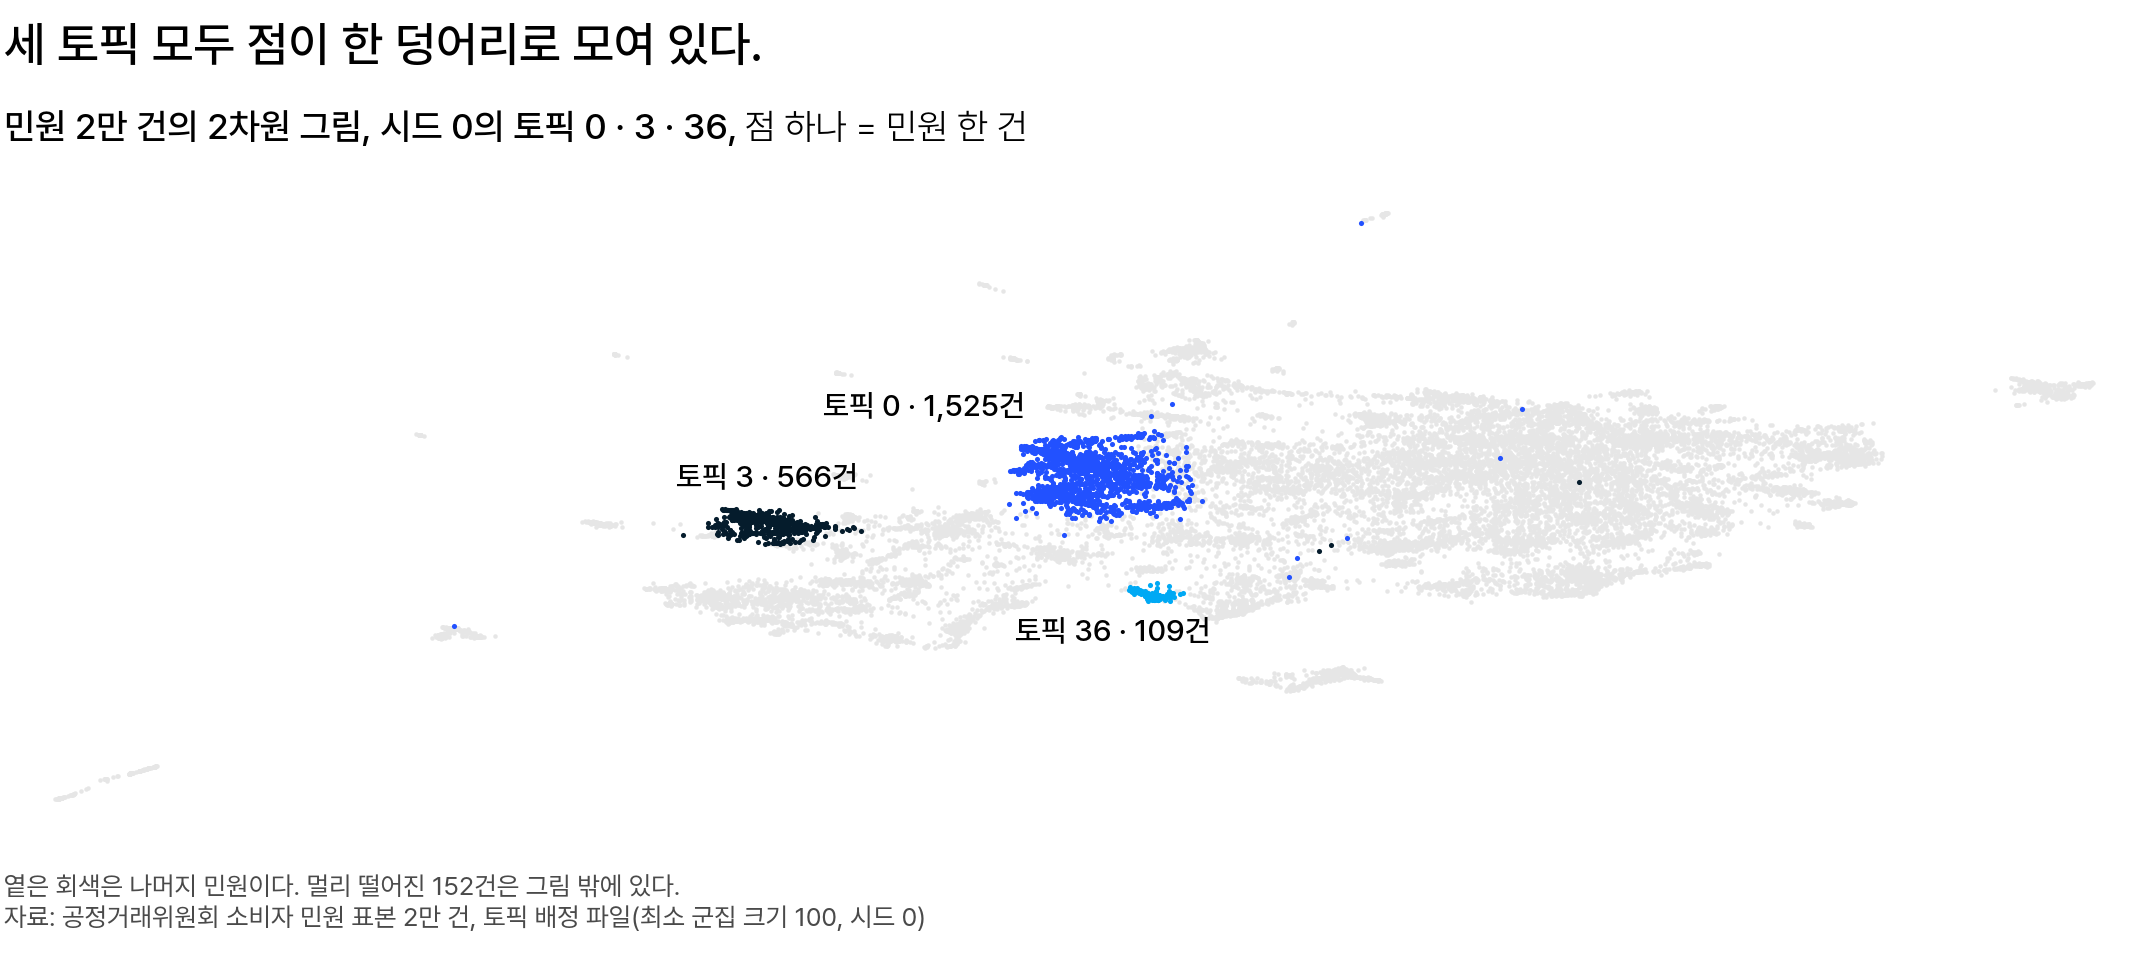

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 점 하나가 민원 한 건이다. 점의 위치는 그림을 그리려고 1,024차원 벡터를 2차원으로 줄인 것이라 가로 · 세로에 단위가 없다. 파랑은 토픽 0, 남색은 토픽 3, 하늘색은 토픽 36 이고, 옅은 회색은 나머지 민원이다</em></p>

**원문을 읽기 전에 사건이 여럿일 토픽을 짐작할 수 있나요?**

토픽 0 · 3 뿐 아니라 토픽 0～7 모두 원문 5건씩을 읽고 원문 검토 결과를 정했습니다. 읽기 전에 그 결과를 짐작할 단서도 원자료에 있어, 더 읽어 볼 토픽을 먼저 고를 수 있습니다.

**상담이유** 는 원자료에서 상담원이 입력한 사유 코드이고, 표본 2만 건에서 16종입니다. 같은 제품이라도 사건이 다르면 상담이유가 AS · 해지 · 품질처럼 달라집니다.

**가장 많은 상담이유의 비중** 은 토픽의 민원 가운데 가장 많이 입력된 상담이유가 차지하는 비율입니다.

```text
가장 많은 상담이유의 비중 = 그 상담이유가 입력된 민원 수 ÷ 토픽의 민원 수
```

- 비중이 높으면 토픽의 민원 대부분이 같은 상담이유라, 사건이 하나일 가능성이 큽니다.
- 비중이 50% 미만이면 상담이유 하나가 토픽의 절반도 안 되어, 사건이 여럿일 수 있습니다.

비중이 50% 미만인 토픽은 원문 읽기에서도 사건이 여럿이었을까요?

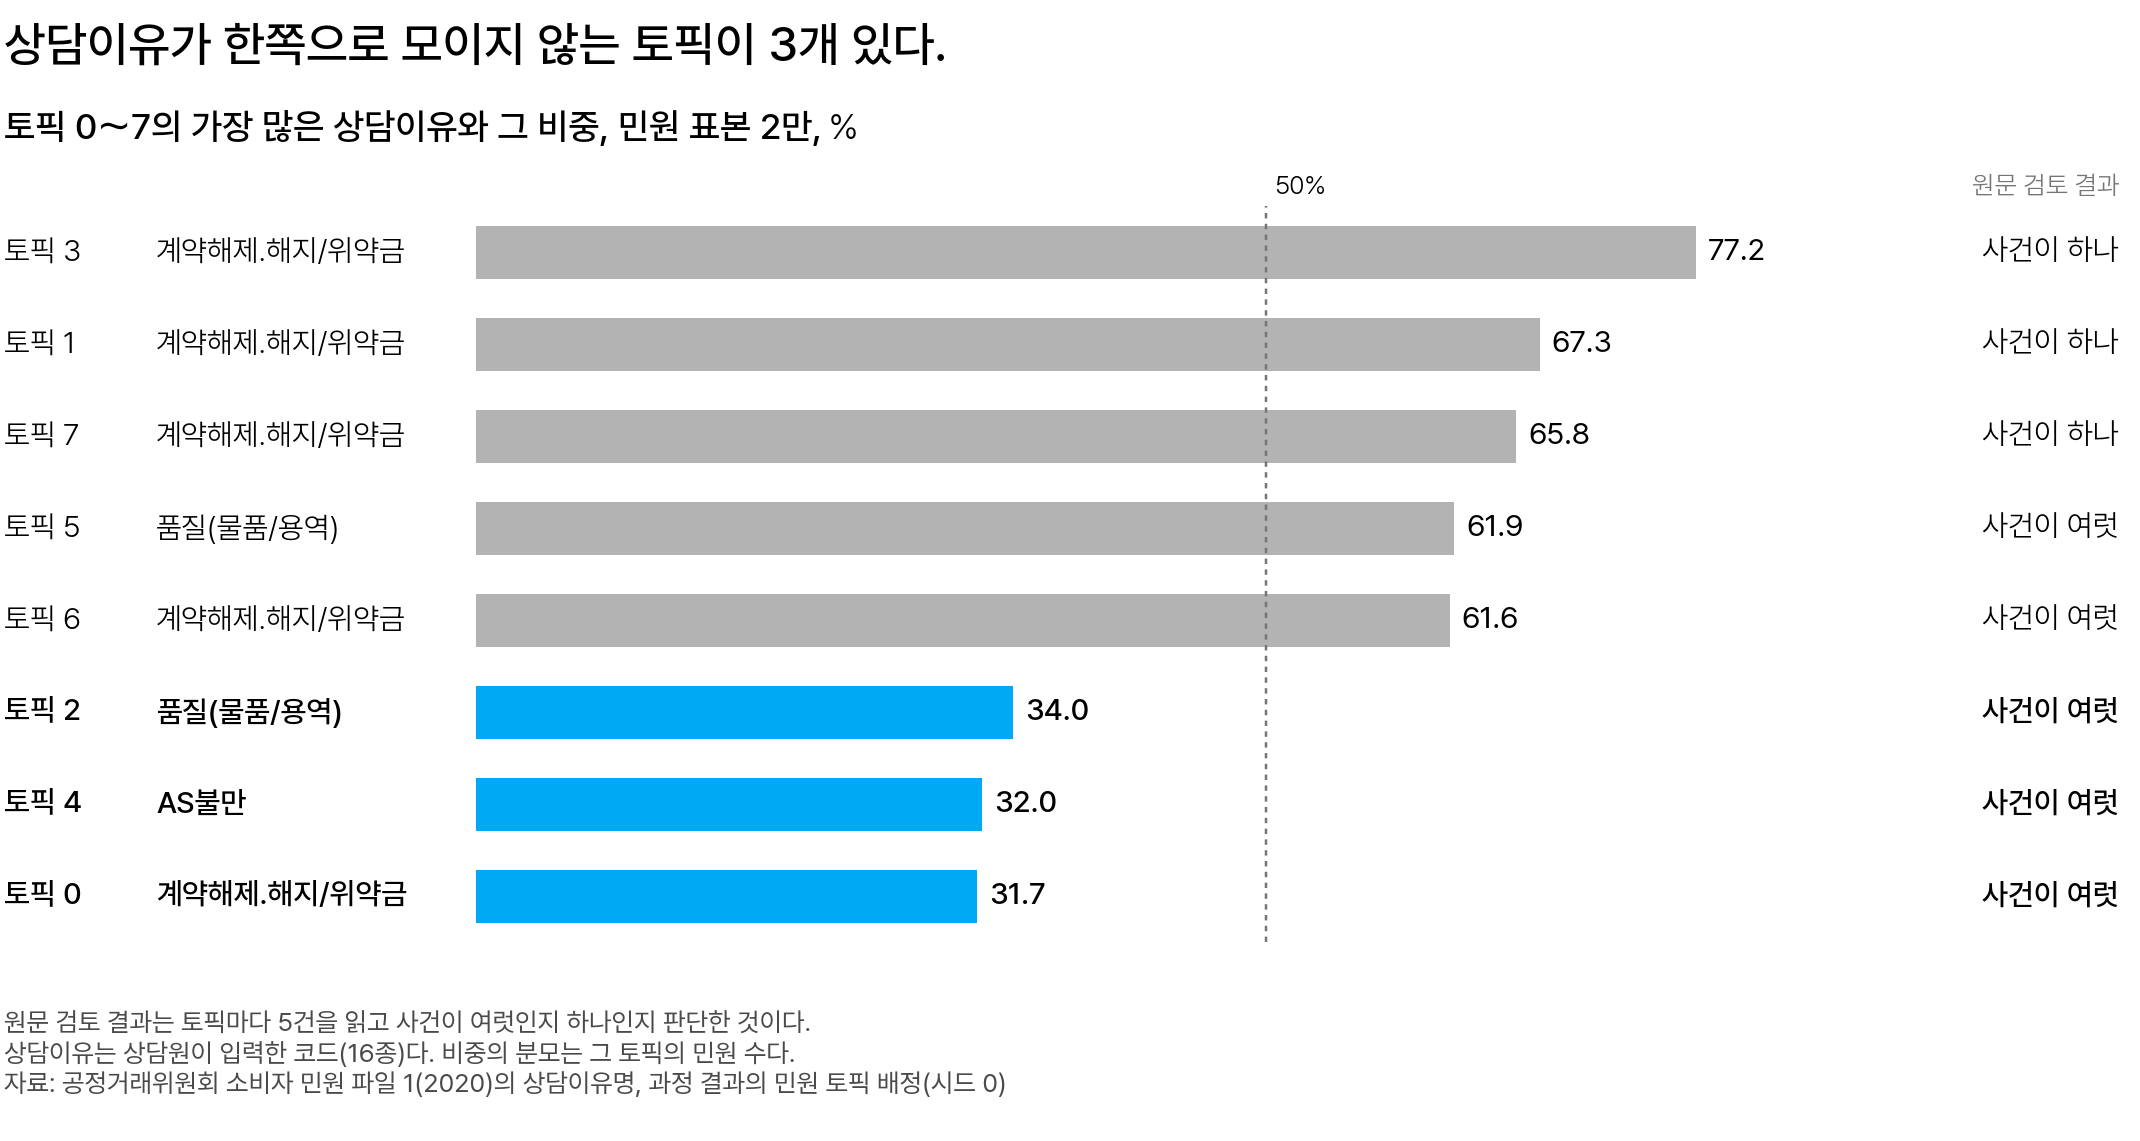

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 막대 하나가 토픽 하나이고, 막대 길이는 그 토픽에서 가장 많은 상담이유의 비중(%)이다. 막대 왼쪽 글자는 토픽 번호와 그 상담이유이고, 오른쪽 끝 글자는 원문 검토 결과다. 하늘색은 비중이 50% 미만인 토픽이고, 세로 점선은 50% 기준이다</em></p>

비중이 50% 미만인 토픽 0 · 2 · 4 는 원문 검토 결과도 모두 「사건이 여럿」입니다. 비중이 낮은 토픽은 원문을 더 읽어 볼 신호가 됩니다.

다만 비중만으로 원문 검토 결과를 정할 수는 없습니다.

- 비중이 높아도 사건이 여럿일 수 있습니다. 토픽 6 은 대표 문서 「결혼 예식 해지시 위약금 문의」와 달리 무작위 2건이 인원 조정을 말합니다. 「예식 계약 인원수 수정 문의」와 「예식장 식사인원 조정관련건」입니다. 토픽 5 도 그렇습니다.
- 가장 많은 상담이유가 같아도 원문 검토 결과는 다릅니다. 토픽 3 과 토픽 6 은 둘 다 계약해제.해지/위약금이지만 토픽 3 만 사건이 하나입니다.

### 시드를 바꿔도 같은 토픽이 나오는가 [필수]

민원 2만 건을 시드 0 · 1 · 2 로 세 번 적합한 배정을 「2. 시드 안정성」의 차례대로 비교합니다. 배정 전체의 ARI 부터 예상해 봅니다.

> **[예측] 시드만 바꾼 세 배정을 두 실행씩 비교하면 ARI 는 어디쯤일까요?**
>
> 1. 0.99 이상: 거의 같다
> 2. 0.8 근처: 큰 틀은 같고 일부가 바뀐다
> 3. 0.5 아래: 크게 바뀐다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

답은 둘째 보기 「0.8 근처: 큰 틀은 같고 일부가 바뀐다」입니다. 세 쌍의 ARI 는 우연 수준 0 보다 같은 배정 1 에 가깝습니다.

```text
0(우연 수준) ──────────────────── 0.82～0.84(BERTopic 세 쌍) ── 1(같은 배정)
```

1 에 못 미치는 것은 주로 이상치(−1) 때문입니다. ARI 는 이상치도 한 군집처럼 비교하는데, 시드 0 · 1 에서 한 시드에서만 이상치인 민원이 1,203건입니다.

```text
두 배정에서 같음 · 다름이 다른 문서 쌍: 약 820만 개(전체 약 2억 쌍의 4.1%)
그 가운데 두 시드 모두 토픽에 속한 민원끼리의 쌍: 약 8만 개
→ 나머지 800만 개 남짓은 어느 한 시드에서라도 이상치인 민원이 포함된 쌍
```

이상치 때문에 같음 · 다름이 바뀐 쌍이 대부분이라 ARI 가 0.82 쯤으로 내려갑니다. 두 시드 모두 토픽에 배정된 민원만 비교하면 ARI 는 세 쌍 모두 약 0.99 입니다.

**토픽 하나씩 보면 몇 개가 다시 나오나요?**

시드 0 토픽 40개마다 시드 1 · 2 에서 각각 자카드 계수가 가장 큰 토픽의 값을 구하고, 두 값 가운데 작은 값을 봅니다. 이 값이 0.5 아래면 한 시드에서라도 대응 토픽이 없습니다.

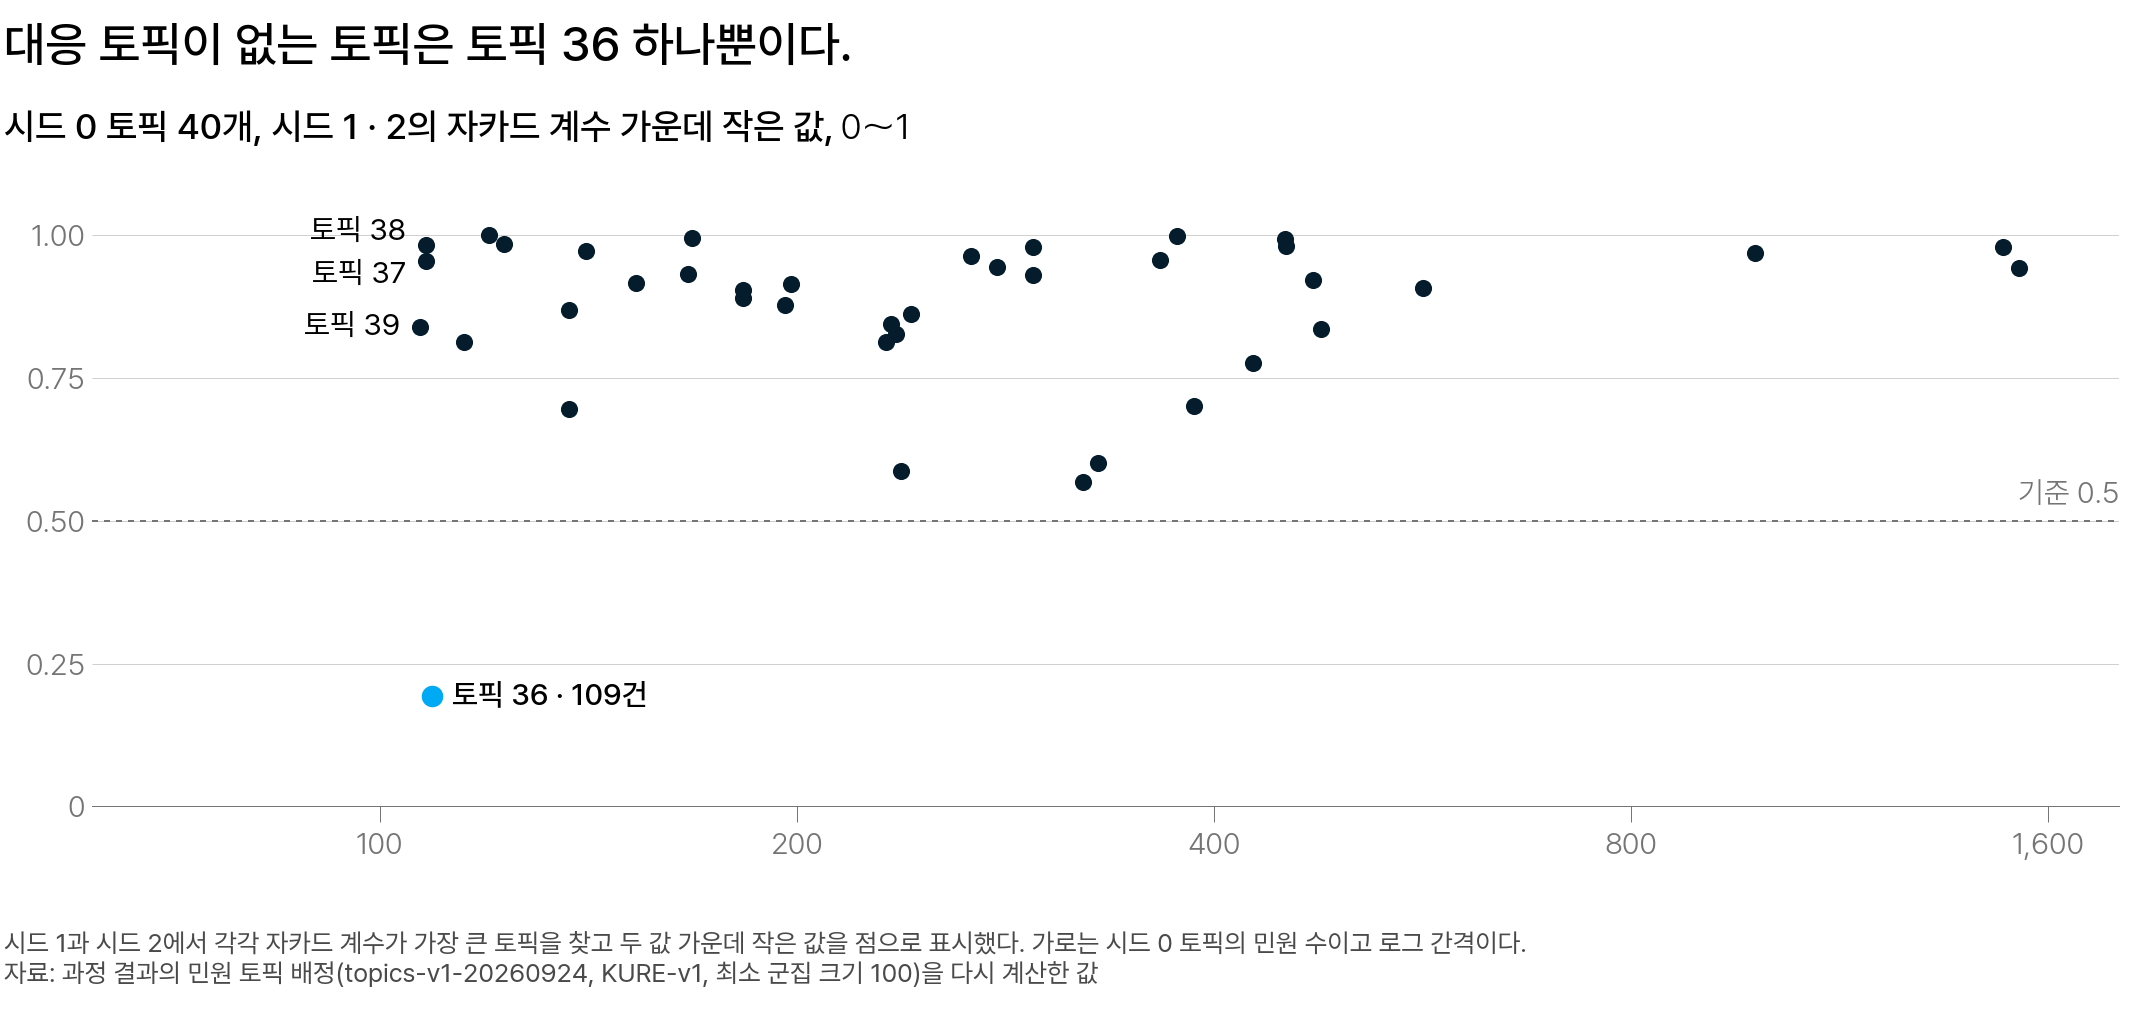

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 점 하나가 시드 0 의 토픽 하나다. 가로축은 그 토픽의 민원 수이고 두 배마다 눈금 하나다. 세로축은 시드 1 · 2 에서 각각 구한 가장 큰 자카드 계수 가운데 작은 값이다. 점선은 대응 토픽의 기준 0.5 이고, 하늘색 점이 토픽 36, 남색 점이 나머지 토픽이다</em></p>

기준 0.5 아래는 토픽 36 하나이고, 토픽 0 을 비롯한 나머지 39개는 다른 두 시드에서도 다시 나옵니다.

크기만으로는 대응 토픽이 있는지 정해지지 않습니다.

- 토픽 36 보다 작은 토픽 37 · 38 · 39 도 두 시드 모두에서 대응 토픽이 있습니다.
- 반대로 큰 토픽이라고 자카드 계수가 늘 1 에 가깝지도 않습니다. 민원 수 상위 10개 토픽 가운데 가장 낮은 토픽 9 는 0.70 이고 0.5 는 넘습니다.

시드 0 에는 의료 토픽이 둘입니다. 토픽 13 은 322건이고, 성형 · 시술 선납의 토픽 36 은 109건입니다. 시드 1 에서는 두 토픽의 민원과 이상치 일부가 의료 토픽 하나에 모입니다.

```text
시드 1 의 의료 토픽 565건 = 토픽 13 에서 321건 + 토픽 36 에서 109건 + 시드 0 이상치에서 135건
```

토픽 36 의 민원은 시드 1 에서 어느 토픽에 배정되었을까요? 두 시드의 배정을 같은 2차원 그림에 색으로 표시합니다.

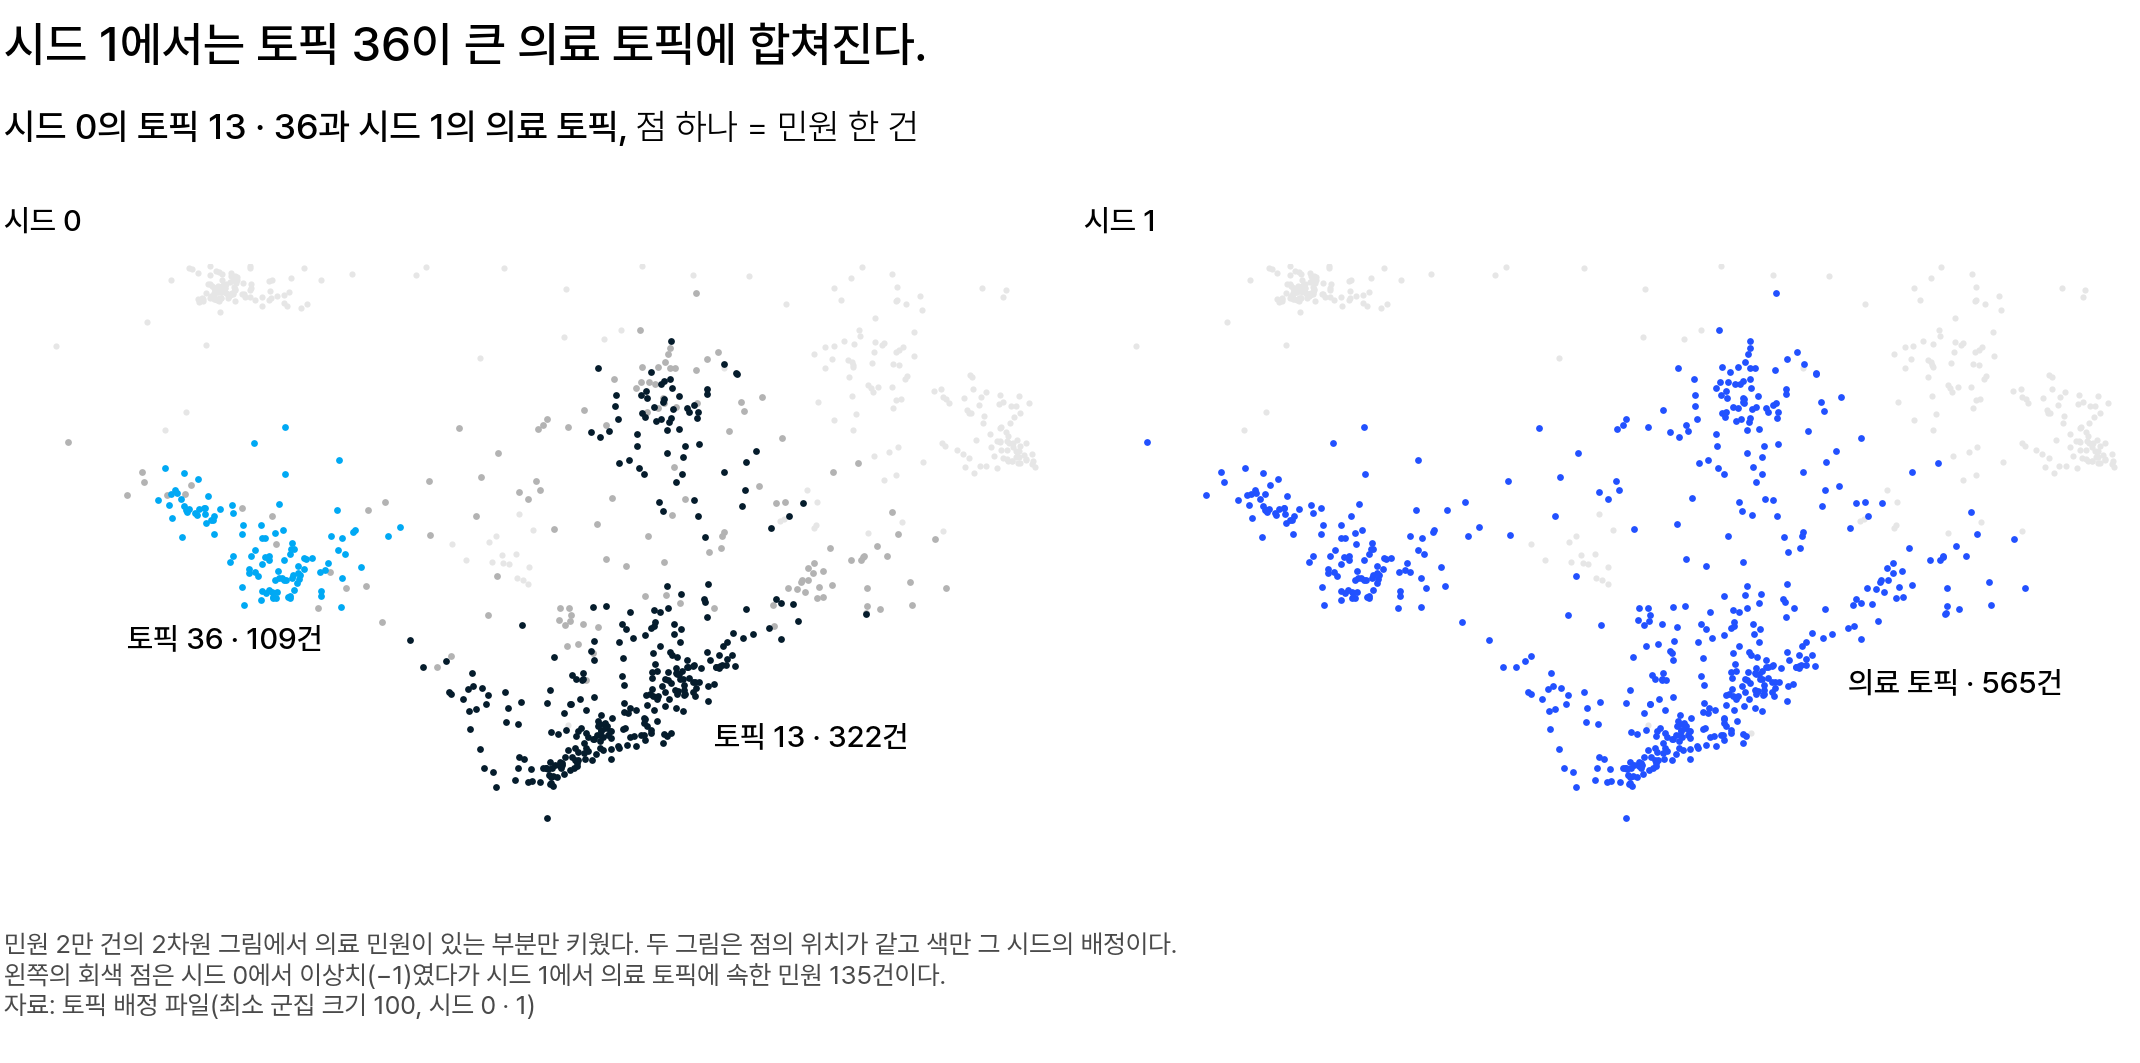

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 점 하나가 민원 한 건이다. 점의 위치는 그림을 그리려고 1,024차원 벡터를 2차원으로 줄인 것이라 두 그림이 같고, 색만 그 시드의 토픽 배정이다. 왼쪽 남색은 토픽 13, 하늘색은 토픽 36, 회색은 시드 0 의 이상치(−1)다. 오른쪽 파랑은 시드 1 의 의료 토픽이고, 옅은 회색은 나머지 민원이다</em></p>

의료 토픽 13 은 합쳐진 뒤에도 시드 1 의 의료 토픽과 절반 넘게 겹쳐 대응 토픽이 있습니다.

**토픽 36 은 민원이 모두 의료 토픽에 속하는데 왜 대응 토픽이 없나요?**

예시의 여행사 패키지 환불처럼, 한 토픽에 모두 있어도 그 토픽이 커서 분모가 커졌기 때문입니다(「2. 시드 안정성」). 패키지 환불 3건은 분모가 7 이라 0.43 이었습니다.

```text
함께 있는 민원: 토픽 36 의 109건 전부
어느 한쪽에라도 있는 민원: 의료 토픽의 565건
자카드 계수: 109 ÷ 565 ≈ 0.19 → 기준 0.5 아래
```

분모로 토픽 36 의 민원 수 109 를 썼다면 1 이 되어, 더 큰 토픽에 합쳐진 것이 드러나지 않습니다. 시드 2 에서도 토픽 36 은 큰 의료 토픽에 합쳐져 대응 토픽이 없습니다.

**ARI 는 1 에 못 미치는데 왜 대응 토픽은 39개나 있나요?**

두 값이 비교하는 대상이 다르기 때문입니다(「2. 시드 안정성」). ARI 를 1 아래로 낮춘 이상치 민원은 대응 토픽을 찾을 때 비교에서 뺍니다.

반대로 시드 1 에서 토픽 36 이 합쳐져 같음 · 다름이 바뀐 쌍은 약 5만 개입니다. 이상치가 포함되어 바뀐 쌍 800만 개 남짓의 1% 에도 못 미쳐, ARI 에 거의 드러나지 않습니다. 그래서 대응 토픽을 따로 확인합니다.

<details class="lms-extra"><summary>자세히 — 토픽 36 으로 계산한 문서 쌍 비율</summary>

시드 1 에서 토픽 36 의 109건은 모두 의료 토픽 565건에 있습니다. 토픽 36 의 민원이 들어간 쌍은 상대 민원에 따라 세 가지입니다.

| 상대 민원 | 시드 0 | 시드 1 |
|---|---|---|
| 토픽 36 의 다른 민원 | 같음 | 같음 |
| 의료 토픽의 나머지 456건(565 − 109) | 다름 | 같음 |
| 의료 토픽 밖의 민원 | 다름 | 다름 |

그래서 같음 · 다름이 바뀌는 쌍은 나머지 456건이 상대인 쌍뿐입니다.

```text
토픽 36 이 합쳐져 바뀐 쌍: 109건 × 나머지 456건 ≈ 5만 개
이상치가 포함되어 바뀐 쌍: 800만 개 남짓
→ 5만 ÷ 800만 ≈ 0.6%, 1% 에도 못 미침
```

</details>

<details class="lms-extra"><summary>더 깊이 — LDA 와 비교한 결과</summary>

**LDA(잠재 디리클레 할당, Latent Dirichlet Allocation)** 는 문서마다 토픽 비중을, 토픽마다 단어 확률을 추정하는 확률 토픽 모델입니다. 두 값은 문서-단어 행렬의 단어 횟수로 추정합니다.

LDA 는 BERTopic 과 달리 토픽 수를 먼저 정해야 합니다. 토픽 모델링 수업에서 월간 요약에 쓸 토픽 표를 12～20개 항목으로 만들기로 했으므로, LDA 의 토픽 수는 가장 작은 12개로 정했습니다. BERTopic 의 40개는 최소 군집 크기 100 으로 나온 수입니다.

ARI 는 우연한 일치를 빼므로 군집 수와 상관없이 우연 수준이 0 입니다. 토픽 수가 40개와 12개로 달라도 두 방법의 ARI 는 나란히 비교할 수 있습니다.

| 비교한 두 실행 | 시드 0 · 1 | 시드 0 · 2 | 시드 1 · 2 |
|---|---:|---:|---:|
| BERTopic(토픽 40개) | 0.8212 | 0.8406 | 0.8214 |
| LDA(토픽 12개) | 0.2094 | 0.1509 | 0.2028 |

LDA 는 시드만 바꿔도 우연 수준 0 에 가까울 만큼 배정이 바뀌어, 다시 적합하면 다른 토픽 표가 됩니다. 민원 제목은 명사가 평균 6.11개뿐이라 문서-단어 행렬이 거의 비어 있습니다. 민원마다 토픽을 정할 단서가 적어, 처음에 무작위로 정하는 시작값이 배정을 크게 좌우합니다.

불용어를 빼기 전과 뒤의 LDA 배정도 ARI 0.1588 로 크게 다릅니다. 반면 BERTopic 의 배정은 임베딩으로 정하므로 불용어를 빼도 바뀌지 않았고(ARI 1.0), 불용어 제거는 상위 단어에만 영향을 줍니다. 짧은 민원 제목의 토픽 표는 LDA 를 한 번 적합한 결과만으로 믿기 어렵습니다.

토픽 비중 θ 와 토픽의 단어 확률 φ 를 구하는 계산과 LDA 를 쓰기에 알맞은 자료는 LDA 수업에서 자세히 다룹니다.

</details>

> **[문제] 같은 민원 2만 건을 시드만 바꿔 다시 적합했습니다. BERTopic 세 쌍의 ARI 는 0.8212 · 0.8406 · 0.8214 였습니다. LDA(단어 횟수로 토픽을 찾는 확률 토픽 모델, 토픽 12개)는 0.2094 · 0.1509 · 0.2028 이었습니다. 이 수로 말할 수 있는 것은 무엇일까요?**
>
> 1. LDA 로 만든 토픽 표는 시드를 바꾸면 문서 배정이 크게 달라져, 다시 적합하면 다른 표가 된다
> 2. BERTopic 은 ARI 가 0.82 이상이므로 토픽 40개가 모두 세 시드에서 다시 나온다
> 3. LDA 의 ARI 가 0.2 쯤이므로 LDA 토픽의 이름 확인은 20% 만 맞는다

### 이름 확인과 코드북 [필수]

이름 확인은 토픽마다 10건 이상을 읽어야 해서, 민원이 가장 많은 토픽 0～7 의 8개만 했습니다. 이 8개에 민원 2만 건의 약 32% 가 속합니다.

**이름 초안은 얼마나 바뀌었나요?**

이름 초안은 예시 토픽 「헬스장」과 같은 모델 · temperature · 프롬프트 버전으로 만들었습니다. 토픽 0 의 초안은 「휴대폰 개통 철회」였습니다. 대표 문서 4건 가운데 3건이 개통 철회 문의였기 때문입니다.

<details class="lms-extra"><summary>자세히 — 토픽 0 에 입력한 프롬프트와 출력</summary>

시스템 프롬프트는 「당신은 소비자 민원을 분석하는 보조입니다.」로 시작합니다. 이어서 토픽 이름과 한 줄 설명을 쓰라는 지시가 있습니다.

그다음 아래 프롬프트를 입력했습니다. `상위어:` 뒤의 단어 10개가 상위 단어입니다.

> `상위어:` 개통, 요금, 휴대폰, 철회, 인터넷, 전화, 이동, 스마트폰, 계약, 해지
>
> `대표 민원 제목:`
>
> - 개통하지 않은 휴대폰 요금 지출에 관한 건
> - 휴대폰 계약과 다르게 계약되어 개통 철회 문의
> - SK휴대폰 계약과 다른 개통철회 문의
> - 전화로 휴대폰 개통시 내용과 달라 개통철회 문의
>
> `형식:`
>
> 이름: (10자 안팎 명사구)
>
> 설명: (한 문장)

출력은 이름과 설명 한 문장입니다.

> 이름: 휴대폰 개통 철회
>
> 설명: 휴대폰 개통 후 요금 지출이나 계약 내용과 다르게 철회를 요청하는 민원

</details>

초안 8개 가운데 그대로 쓴 것은 토픽 4 · 7 의 2개이고, 나머지 6개는 이름 확인을 거치며 고쳤습니다.

| 토픽 | LLM 이름 초안 | 최종 이름 |
|---|---|---|
| 0 | 휴대폰 개통 철회 | 통신·인터넷·광고 계약 해지와 요금 |
| 1 | 국외여행 취소 | 여행·숙박·항공 취소 환불 |
| 2 | 중고차 보증 수리 | 자동차·오토바이 구입·수리·렌트·보험 |
| 3 | 해지 환불 민원 | 헬스장·운동 강습 중도 해지 환불 |
| 4 | 정수기 렌탈 민원 | 정수기 렌탈 민원 |
| 5 | 세탁 관련 민원 | 세탁·수선 사고(훼손·분실) |
| 6 | 코로나 예식 취소 | 예식 취소·위약금 |
| 7 | 주식자문 계약 | 주식자문 계약 |

민원 2만 건의 이름 확인에서는 민원 제목과 품목명을 함께 읽고 판단했습니다. 품목명은 원자료에서 제품 이름이 있는 열입니다. 판단 예 3건은 코드북 v0 을 만들 때 이름 확인에서 읽은 10건 가운데서 골랐습니다. 맞음과 아님은 과정을 만들 때 AI 가 판단했고, 사람이 판단한 값은 아닙니다.

| 토픽 | 확인한 이름 | 민원 제목(원자료) | 품목명 | 판단 | 이유 |
|---:|---|---|---|---|---|
| 4 | 정수기 렌탈 민원 | 청호나이스 매트리스 AS관련 불만으로 전체위면해지 요청 | 침대 | 아님 | 청호나이스는 정수기 렌탈로 알려진 회사지만, 제품이 매트리스다 |
| 3 | 헬스장·운동 강습 중도 해지 환불 | 헬스장 업체 대표가 변경되어 계약내용이  달라졌다고 함. | 헬스장 | 아님 | 제품은 헬스장이지만 해지 · 환불이 아니라 계약 내용 변경을 말한다 |
| 7 | 주식자문 계약 | 로또정보이용서비스 가입 후 중도해지 후 환급금 지급 요구 | 기타정보이용서비스 | 아님 | 중도해지는 맞지만 서비스가 주식자문이 아니다 |

판단은 이름의 단어 하나가 아니라 **제품과 사건이 함께 맞는지**로 합니다. 토픽 4 「정수기 렌탈 민원」처럼 이름에 사건이 없으면 제품으로만 판단합니다. 토픽 4 의 그 10건에서는 정수기 수리 · 교환 · 해지 요청이 모두 맞음이었습니다.

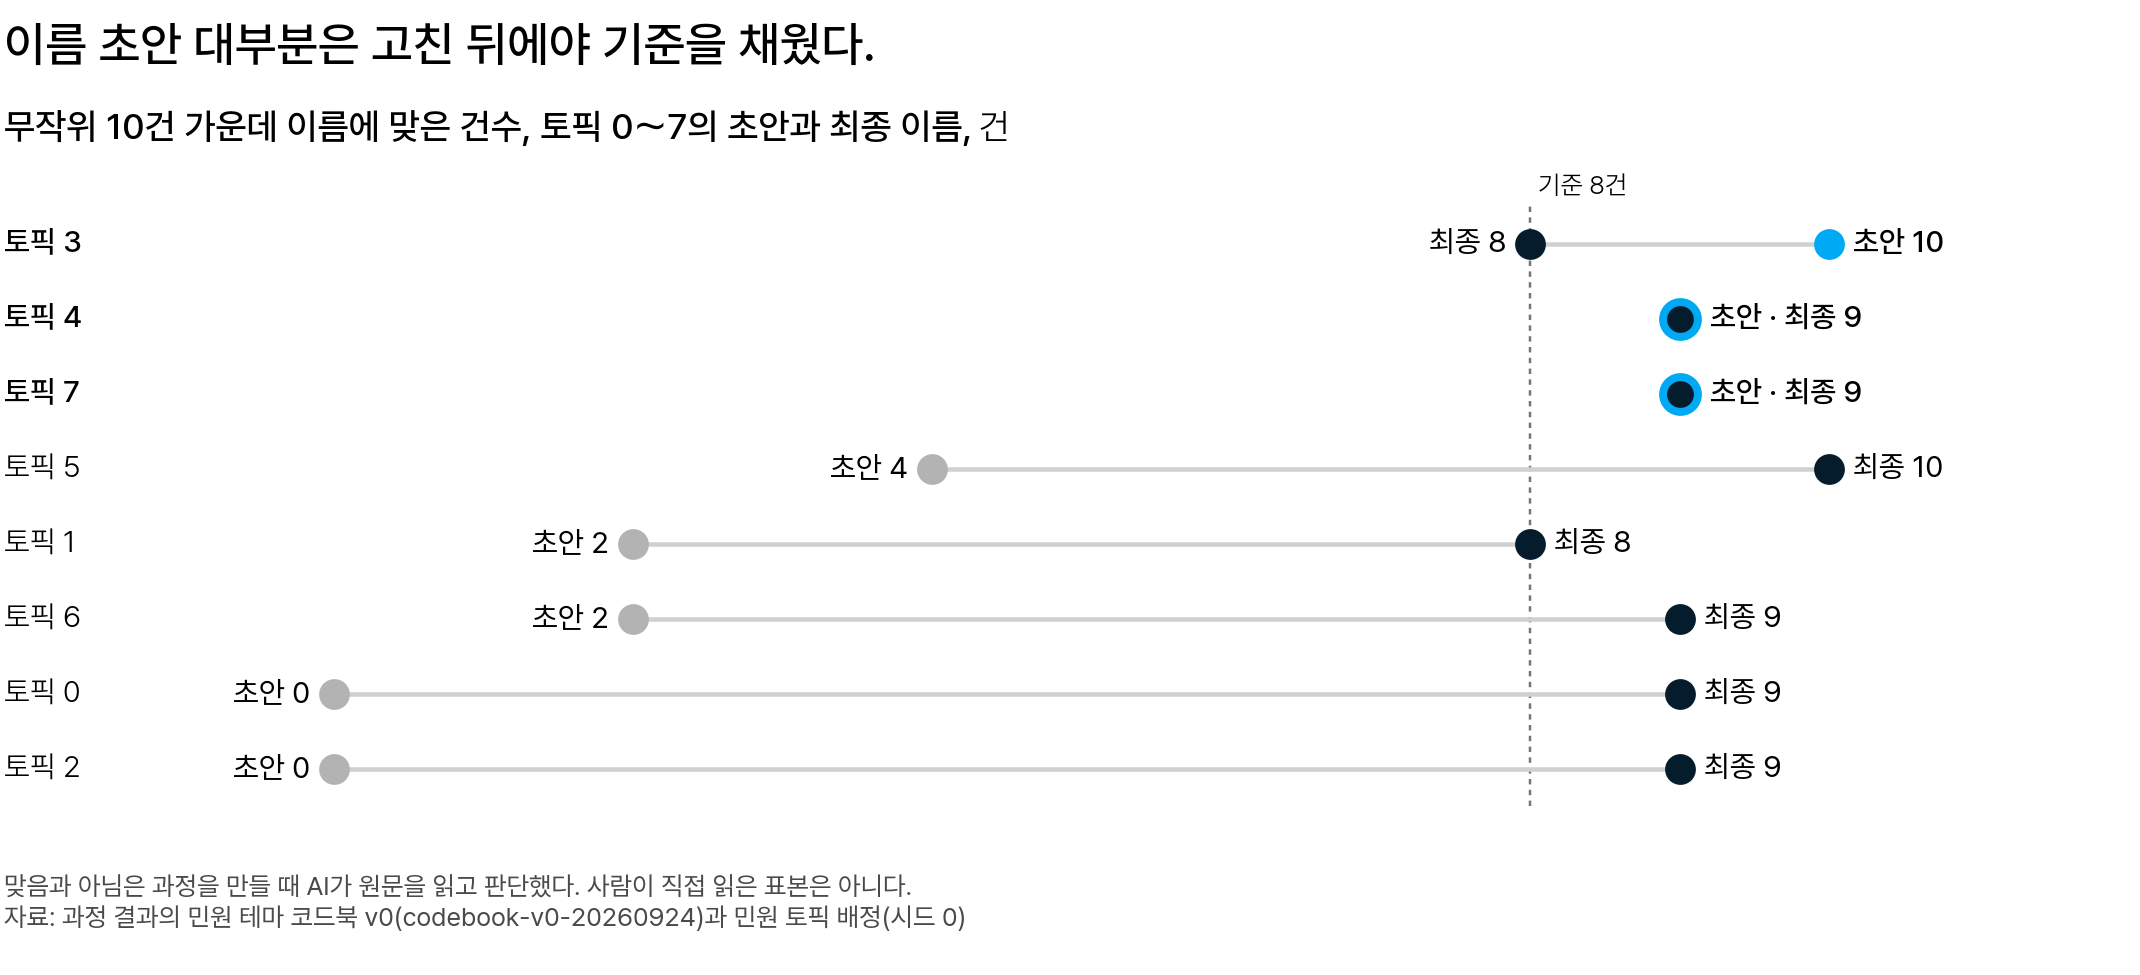

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 행 하나가 토픽 하나이고, 가로 위치는 무작위 10건 가운데 이름에 맞은 건수다. 하늘색 · 회색 점은 이름 초안이고 남색 점은 최종 이름이다. 하늘색은 처음부터 8건 이상 맞은 초안이고, 가는 회색 선은 같은 토픽의 두 점을 잇는다. 세로 점선은 기준 8건이다</em></p>

**고친 초안에는 어떤 문제가 있었나요?**

「4. 이름 확인」의 예시 토픽에서 본 세 가지 문제가 실제 초안에도 나왔습니다.

- 좁은 이름(토픽 0 「휴대폰 개통 철회」): 예시의 「헬스장 위약금」처럼 사건 하나만 말합니다. 첫 확인 10건에는 개통 철회가 하나도 없었습니다.
- 넓은 이름(토픽 3 「해지 환불 민원」): 예시의 「회원권 환불 민원」처럼 제품이 없는 넓은 이름입니다. 첫 확인 10건은 모두 맞았습니다. 토픽 1 의 여행 취소 환불 민원에도 들어맞을 수 있어 헬스장을 더해 고쳤습니다.
- 원인을 포함한 이름(토픽 6 「코로나 예식 취소」): 예시의 「코로나 헬스장 환불」처럼 원인을 이름에 포함했습니다. 첫 확인 10건은 대부분 코로나를 말하지 않은 예식장 취소 · 위약금 문의였습니다. 이름에는 유형만 남기고, 코로나는 코드북의 원인 항목에 적었습니다.

넓은 이름 「해지 환불 민원」에 맞은 10건에는 헬스장이 아닌 민원도 있었습니다.

> 「스타디룸 비용 환불」(원자료 표기, 품목명 기타미분류서비스)

이름을 좁히면 맞은 건수가 줄 수 있지만, 8건 이상이면 기준을 통과합니다.

<details class="lms-extra"><summary>자세히 — 「휴대폰 개통 철회」 첫 확인 10건 가운데 4건</summary>

4건만 보아도 품목명이 모두 다릅니다.

- 이사시 해지한 인터넷 요금 부당 청구 환급 가능 문의(초고속인터넷)
- 전화상담 받고 광고 계약후 취소 위약금 부과 문의(기타매체광고)
- 신용카드 조회기 계약해지건(신용카드조회기)
- 핸드폰 번호도용으로 인한 피해금액 환불 요구(이동전화서비스)

</details>

**코드북 v0 은 어떻게 되어 있나요?**

**코드북 v0**(민원 테마 코드북 v0)은 토픽 0～7 의 이름을 확인해 만든 테마 8개의 첫 판입니다. 코드북 v0 파일의 8개 항목은 모두 포함 기준과 제외 기준이 아래 일반 문장 두 개입니다.

> 포함 기준: 제목·품목명이 이 이름에 들어맞는 민원
>
> 제외 기준: 다른 테마 이름이 더 잘 맞는 민원 → 그 테마, 어디에도 맞지 않으면 기타

두 문장은 이름만 있을 때와 다르지 않습니다. 「5. 코드북」의 분석가 두 명처럼 사람마다 애매한 민원을 다르게 나눌 수 있습니다. 예를 들어 돌잔치 계약 취소를 「예식 취소·위약금」에 포함할지 이 문장으로는 정할 수 없습니다.

**토픽 6 의 기준은 어떻게 다시 썼나요?**

토픽 6 의 항목은 이 수업에서 이름 확인의 원문으로 기준을 다시 썼습니다. 이름과 예는 코드북 v0 그대로입니다.

| 항목 | 토픽 6 「예식 취소·위약금」 |
|---|---|
| 정의 | 예식장·웨딩홀·결혼준비대행 계약을 취소·연기·변경하면서 생긴 위약금·계약금 문제에 관한 민원 |
| 포함 기준 | 민원 제목이 예식 계약의 취소·연기·인원 조정이나 그에 따른 위약금·계약금 환급을 말한다 |
| 제외 기준 | 돌잔치 · 뷔페 계약의 취소와 결혼정보업체 가입비는 예식 계약이 아니라 기타 |
| 예 | 「코로나로 인한 예식장해지문의」 · 「예식장 계약해제시 계약금 환급 문의」 |
| 원인 | 민원 제목에 코로나가 있으면 「코로나」, 없으면 비운다 |

예시 항목에서 양도 · 불친절이 제외 기준이 된 것처럼, 두 기준은 이름 확인의 원문으로 정했습니다.

- 「코로나로 인한 뷔페취소」(품목명 외식)는 이름 확인에서 「아님」이었습니다. 예식 계약이 아니므로 제외 기준에 적었습니다.
- 「이번주 토요일 예식 앞두고 날짜연기가능한지문의」는 사건이 이름의 「취소」가 아니라 연기입니다. AI 는 맞음으로 판단했고, 연기도 예식 계약을 바꾸는 민원이라 포함 기준에 연기를 적었습니다. 기준대로도 맞음이라 9/10 은 그대로입니다.

**나머지 7개는 테마로 쓸 수 있나요?**

이번 달에는 씁니다. 이번 달 테마 건수는 토픽 배정으로 집계하므로, 기준을 고쳐도 건수는 바뀌지 않습니다. 다만 다음 달 자료를 나누거나 LLM 으로 분류하기 전에는 7개의 기준을 토픽 6 처럼 원문으로 다시 씁니다.

### 어느 토픽을 테마로 쓰는가 [필수]

세 가지 확인(원문 읽기 · 시드 안정성 · 이름 확인)의 결과를 토픽마다 한 표로 모았습니다.

| 토픽 | 민원 수 | 원문 검토 결과 | 자카드 계수(두 시드 가운데 작은 값) | 테마 이름 | 이름 확인 |
|---:|---:|---|---:|---|---:|
| 0 | 1,525 | 사건이 여럿 | 0.94 | 통신·인터넷·광고 계약 해지와 요금 | 9/10 |
| 1 | 1,484 | 사건이 하나 | 0.98 | 여행·숙박·항공 취소 환불 | 8/10 |
| 2 | 983 | 사건이 여럿 | 0.97 | 자동차·오토바이 구입·수리·렌트·보험 | 9/10 |
| 3 | 566 | 사건이 하나 | 0.91 | 헬스장·운동 강습 중도 해지 환불 | 8/10 |
| 4 | 478 | 사건이 여럿 | 0.83 | 정수기 렌탈 민원 | 9/10 |
| 5 | 472 | 사건이 여럿 | 0.92 | 세탁·수선 사고(훼손·분실) | 10/10 |
| 6 | 451 | 사건이 여럿 | 0.98 | 예식 취소·위약금 | 9/10 |
| 7 | 450 | 사건이 하나 | 0.99 | 주식자문 계약 | 9/10 |
| 36 | 109 | 하지 않음 | 0.19 | 없음(뺌) | 하지 않음 |

토픽 0～7 은 세 가지 확인을 모두 통과했습니다.

- 원문 읽기는 토픽을 빼는 확인이 아니라 이름과 포함 기준의 근거이므로(「1. 원문 읽기」), 사건이 여럿인 토픽도 통과합니다.
- 시드 안정성은 자카드 계수가 모두 0.5 를 넘습니다.
- 이름 확인은 모두 8건 이상입니다.

테마 이름끼리 같은 제품 · 사건을 말하지도 않습니다. 8개 모두 코드북 v0 에 항목이 있어, 기준을 아직 다시 쓰지 않은 7개도 이번 달 테마로 씁니다.

**사건이 여럿인 토픽은 테마 이름만으로 충분할까요?**

표에서 토픽 5개는 원문 검토 결과가 「사건이 여럿」입니다. 이름 확인을 통과해도 사건이 여럿인 것은 그대로입니다.

토픽 0 의 고친 이름은 위약금 · 기기값 청구 · 요금 자동 출금을 모두 「계약 해지와 요금」 하나로 부릅니다. 이름만으로는 CX 팀장이 어느 사건부터 줄일지 정할 수 없습니다. 그래서 「기기값 과다청구로인한철회요청」 · 「동의없던 요금 자동출금되어 문의 2」처럼 사건마다 원문 한 건씩을 함께 보냅니다.

**세 가지 확인을 모두 거친 테마 이름은 틀림없이 민원에 맞나요?**

아닙니다. 그 이름이 토픽의 민원 절반 넘게 맞는다고 틀림없이 말할 수는 없습니다. 무작위 10건을 새로 고르면 맞은 건수와 구간도 달라지기 때문입니다(「4. 이름 확인」).

확인 결과와, 맞음 · 아님을 AI 가 판단했는지에 따라 할 일이 다릅니다.

| 상황 | 권장 방식 |
|---|---|
| 이름 확인이 7건 이하 | 원문을 읽어 이름을 고치고 새 10건으로 다시 확인한다 |
| 8건으로 통과(토픽 1 · 3) | 하한이 0.5 에 가까우므로 CX 팀장에게 보내는 월간 불만 요약에 쓰기 전에 매번 새 10건으로 다시 확인한다 |
| 원문 검토 결과가 「사건이 여럿」 | 사건별 건수가 필요할 때만 토픽을 나눌지 따로 본다 |
| 다른 시드에 대응 토픽이 없음(토픽 36) | 테마로 쓰지 않고, 다시 적합한 뒤 대응 토픽이 생기는지 확인한다 |
| 맞음 · 아님을 AI 가 판단 | 같은 10건을 사람이 읽고 다시 판단한다. 이름은 그대로 두고 판단만 다시 하므로 같은 10건을 쓴다 |

<div class="lms-summary">

**정리**

토픽 40개 가운데 테마는 세 가지 확인을 마친 토픽 0～7 의 8개이고, 다른 시드에 대응 토픽이 없는 토픽 36 은 뺍니다. 이름 초안 8개 가운데 6개는 이름 확인으로 고쳤습니다.

**할 일**

- 이름 확인 건수를 읽을 때는 AI 판단인지 사람 판단인지 먼저 확인합니다
- 다음 달 자료를 나누기 전에 기준을 아직 다시 쓰지 않은 테마 7개의 포함 · 제외 기준을 원문으로 다시 씁니다

세 가지 확인을 모두 거치고 코드북 항목이 있는 토픽만 테마 이름으로 부릅니다.

</div>

> **[문제] 시드 안정성과 이름 확인으로 각각 알 수 있는 것**
>
> 토픽 0 은 다른 두 시드에서 자카드 계수 0.94 · 0.96 으로 대응 토픽이 있습니다. 그런데 LLM 이 낸 이름 초안 「휴대폰 개통 철회」는 무작위 10건 가운데 0건이 맞았습니다. 시드 안정성과 이름 확인이 각각 무엇을 확인하는지 한 문장씩 적어 보세요. 이 토픽이 테마가 되려면 무엇이 더 필요한지도 한 문장으로 써 보세요.

### 팀 라운드: 월간 불만 요약에 포함할 토픽 [필수]

아래 질문의 답은 수업에서 팀이 함께 정합니다. 지금은 자기 답과 근거만 적어 두면 됩니다.

각자 답과 확신도(1～5)를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거 세 문장을 나눠 토론한 뒤 팀이 답 하나로 모아 제출합니다.

> **[문제] 팀 라운드: 월간 불만 요약에 포함할 토픽은 어느 것인가**
>
> 팀은 CX 팀장에게 보낼 월간 불만 요약을 정리하고 있습니다. 테마 8개(토픽 0～7)는 세 가지 확인과 코드북 항목을 모두 거쳐 정했고, 아직 테마가 아닌 시드 0 의 토픽 17 · 36 을 어떻게 다룰지 남았습니다. 토픽 17 은 LLM 이름 초안이 「피해구제 접수」이고, 원문 3건을 읽은 팀원이 「피해구제 절차 문의」로 부르는 토픽입니다.
> 
> - **토픽 17 · 267건** 시드 1 · 2 와의 자카드 계수 0.96 · 0.96(0.5 이상이면 대응 토픽), 이름 확인 · 코드북 항목 없음
> - **토픽 17 의 상담이유** 267건 가운데 73.4% 가 「단순문의.상담」(불만 접수가 아닌 문의)
> - **토픽 36 · 109건** 자카드 계수 0.19 · 0.19, 시드 1 에서는 109건 모두 565건인 의료 토픽 하나에 속함
> - **토픽 36 의 20대 비중** 23.85%, 표본 전체의 2.19배
> 
> 팀 안에서 의견이 3가지로 나뉘었습니다.
> 
> - **관점 A: 토픽 36 을 20대 새 이슈로 요약 맨 앞에서 다룬다.** 109건이 흩어지지 않고 시드 1 의 한 토픽에 모두 모였으니, 0.19 는 그 토픽이 커서 낮게 나왔을 뿐이다. 20대 비중이 표본 전체의 2.19배라 팀장이 먼저 알아야 할 새 이슈다.
> - **관점 B: 토픽 17 · 36 모두 이번 달 요약에 포함하지 않는다.** 팀장이 묻는 것은 불만이고, 요약에는 세 가지 확인을 모두 거친 테마만 포함한다. 두 토픽 모두 이름 확인과 코드북 항목이 없으니 확인을 마친 뒤에 다시 정한다.
> - **관점 C: 토픽 17 은 「피해구제 절차 문의」 건수를 운영 지표로 따로 알리고, 토픽 36 은 뺀다.** 토픽 17 은 불만이 아닌 절차 문의라 불만 요약에서는 빼지만, 두 시드에서 거의 그대로 다시 나오므로 운영팀이 알아야 할 건수다.
> 
> 자기 입장 하나와 근거 세 문장, 다음에 확인할 일 하나, 그리고 확신도를 정하세요.